### 1st cell

In [25]:
import os, heapq, itertools, time, warnings
from datetime import date

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

import gymnasium as gym
from gymnasium import spaces

from stable_baselines3.common.vec_env import SubprocVecEnv
from stable_baselines3.common.monitor import Monitor
from stable_baselines3.common.callbacks import BaseCallback
from sb3_contrib import MaskablePPO
from sb3_contrib.common.wrappers import ActionMasker
from scipy.interpolate import RegularGridInterpolator

### 2nd PDE, grid and exact solution
Burgers: $u_t + a(u)\,u_x = \alpha u_{xx}$ with $a(u)=u$, on $[0,1]$, $u=0$ at both walls, $u(x,0)=\sin\pi x+\tfrac12\sin2\pi x$, $\alpha=0.1$.
Exact solution by Hopf–Cole: $u=-2\alpha\,\phi_x/\phi$, where $\phi$ solves the heat equation with $\phi_x=0$ at the walls (a cosine series).
The exact solution is only used to check results, never by the agent.

inflow_smooth: alpha = 0.1, T = 0.5 | nx = 50, nt = 276, dx = 0.02041, dt = 1.818e-03 | r = 0.44, nu_max = 0.16, 2r + nu^2 = 0.90
check: FD on a grid 1x finer vs u_true at t = 0.25: max error 1.9e-03
check: FD on a grid 2x finer vs u_true at t = 0.25: max error 4.7e-04
check: FD on a grid 4x finer vs u_true at t = 0.25: max error 1.2e-04


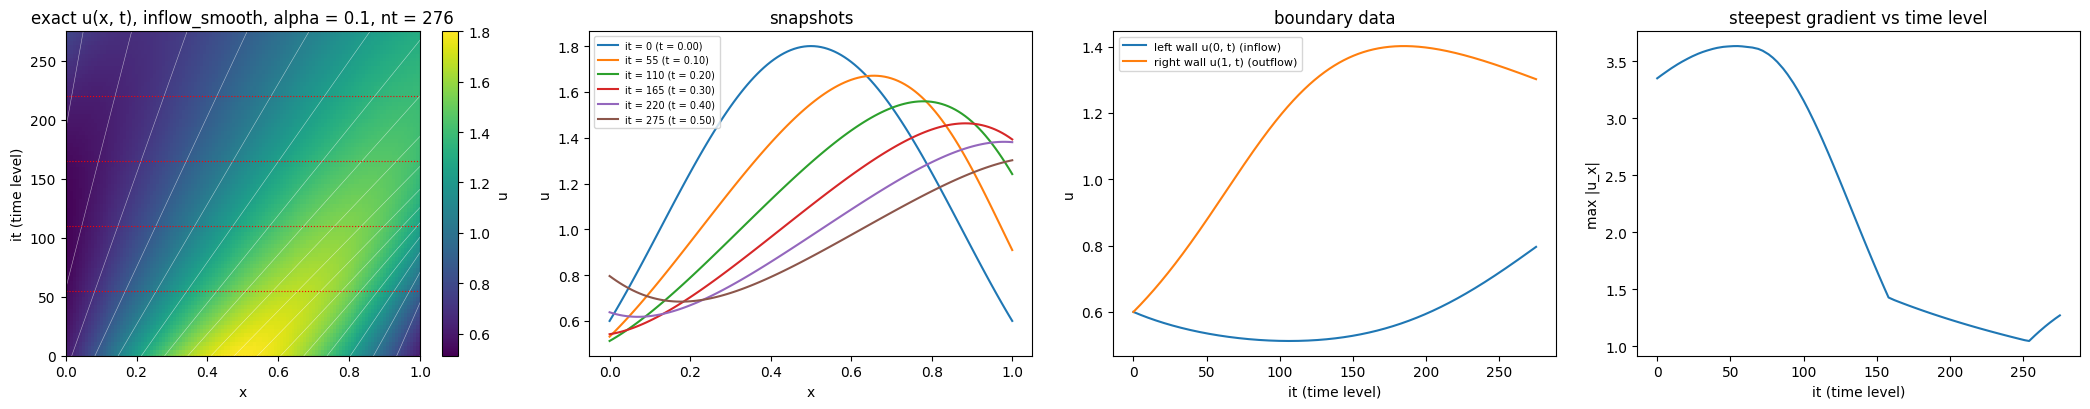

In [26]:
# ── Problem settings: change PROBLEM, everything below follows ──
#   "walls"         : u0 = sin(pi x) + 0.5 sin(2 pi x), u = 0 at both walls, alpha = 0.1   (notebook 12, for comparison)
#   "inflow_smooth" : u0 = 1 + 0.8 sin(2 pi x / 1.5), time-dependent Dirichlet data from the exact solution, alpha = 0.1
#   "inflow_front"  : same, alpha = 0.01: a front forms and leaves (t ~ 0.25-0.35); a second one enters through the left wall (t ~ 0.7)
PROBLEM = "inflow_smooth"   # "walls", "inflow_smooth", or "inflow_front"
alpha, T = {"walls": (0.1, 0.5), "inflow_smooth": (0.1, 0.5), "inflow_front": (0.01, 1.1)}[PROBLEM]

# ── PDE:  u_t + a(u) u_x = alpha u_xx  on [0, 1] ──
a = lambda u: u                                # advection speed: Burgers
if PROBLEM == "walls":
    u0 = lambda x: np.sin(np.pi * x) + 0.5 * np.sin(2 * np.pi * x)
    F0 = lambda x: (1 - np.cos(np.pi * x)) / np.pi + (1 - np.cos(2 * np.pi * x)) / (4 * np.pi)   # integral of u0 from 0
    A_MAX = 1.5                                # bound on |u| (the IC peaks at about 1.26)
else:
    C_BG, A_W, L_W = 1.0, 0.8, 1.5             # background speed, amplitude, wavelength: u stays in [0.2, 1.8] > 0
    X_PK = 0.5                                 # the peak starts at the middle, so u changes a lot there
    u0 = lambda x: C_BG + A_W * np.cos(2 * np.pi * (x - X_PK) / L_W)
    F0 = lambda x: C_BG * x + A_W * L_W / (2 * np.pi) * (np.sin(2 * np.pi * (x - X_PK) / L_W) + np.sin(2 * np.pi * X_PK / L_W))
    A_MAX = C_BG + A_W

# ── Grid ──
# explicit advection + diffusion (LW, FD-3) is stable for 2r + nu^2 <= 1, r = alpha dt/dx^2, nu = A_MAX dt/dx; 0.9 for margin
nx = 50
dx = 1.0 / (nx - 1)
_c2, _c1 = (A_MAX / dx)**2, 2 * alpha / dx**2
nt = int(np.ceil(T / ((-_c1 + np.sqrt(_c1**2 + 4 * _c2 * 0.9)) / (2 * _c2)))) + 1
dt = T / (nt - 1)
x_grid = np.arange(nx) * dx

# ── Exact solution (Hopf-Cole), as a weighted average so it stays accurate for small alpha ──
#    u(x, t) = sum (x - y)/t W / sum W,   W = exp(-F0(y)/(2 alpha) - (x - y)^2 / (4 alpha t)),   y on a uniform grid.
#    "walls": F0 mirrored about every wall (even, period 2) -> phi_x = 0 -> u = 0 at x = 0 and 1.
#    inflow : the whole line, no mirrors; the weight peaks near the foot of the characteristic, y ~ x - u t,
#             so the y range reaches A_MAX * T to the left. Both cover 8 kernel widths. Exponents shifted by their max.
_s = 8 * np.sqrt(2 * alpha * T)
if PROBLEM == "walls":
    _lo, _hi = -np.ceil(_s), 1 + np.ceil(_s)
    _Y  = np.linspace(_lo, _hi, int(round((_hi - _lo) * 10000)) + 1)
    _yf = np.mod(_Y, 2.0)
    _FY = F0(np.where(_yf > 1, 2 - _yf, _yf)) / (2 * alpha)
else:
    _lo, _hi = -A_MAX * T - _s, 1 + _s
    _Y  = np.linspace(_lo, _hi, int(round((_hi - _lo) * 10000)) + 1)
    _FY = F0(_Y) / (2 * alpha)

def u_true(x, t):
    x = np.atleast_1d(np.asarray(x, dtype=float))
    if t <= 0:
        return u0(x)
    out = np.empty(len(x))
    for i in range(0, len(x), 50):                             # chunks of x, to keep memory small
        xs = x[i:i + 50, None]
        E  = -_FY - (xs - _Y)**2 / (4 * alpha * t)
        W  = np.exp(E - E.max(axis=1, keepdims=True))
        out[i:i + 50] = ((xs - _Y) / t * W).sum(1) / W.sum(1)
    return out

# exact values on the grid, one time level at a time when first needed (u_true ONLY for checks, reports, and wall data)
_U_rows = {}
def U_row(it):
    if it not in _U_rows:
        _U_rows[it] = u_true(x_grid, it * dt)
    return _U_rows[it]
Ug = lambda q: U_row(q[1])[q[0]]

# ── Boundary data: u at x = 0 and x = 1 as functions of t (given data, like the IC) ──
# on the grid's time levels it is exact (U_row); between levels (refined classical schemes) a cubic spline through a fine table
from scipy.interpolate import CubicSpline
_tb = np.linspace(0.0, T, 2001)
_gb = np.array([u_true([0.0, 1.0], t) for t in _tb])            # (time, [left, right])
_gs = CubicSpline(_tb, _gb)                                     # cubic in t: accurate enough for high-order schemes too
g_left  = lambda t: float(_gs(t)[0])
g_right = lambda t: float(_gs(t)[1])

r_, nu_ = alpha * dt / dx**2, A_MAX * dt / dx
print(f"{PROBLEM}: alpha = {alpha}, T = {T} | nx = {nx}, nt = {nt}, dx = {dx:.5f}, dt = {dt:.3e} | "
      f"r = {r_:.2f}, nu_max = {nu_:.2f}, 2r + nu^2 = {2 * r_ + nu_**2:.2f}")

# ── Check: an explicit FD solve (with the same boundary data) on finer grids must converge to u_true (error / 4 per halving) ──
def _fd_fine(k, t_end):
    n, h = (nx - 1) * k + 1, dx / k
    steps = int(np.ceil(t_end / min(0.2 * h**2 / alpha, 0.5 * h / A_MAX))); s = t_end / steps
    u = u0(np.arange(n) * h)
    for j in range(steps):
        u[1:-1] = u[1:-1] + alpha * s / h**2 * (u[2:] - 2 * u[1:-1] + u[:-2]) - u[1:-1] * s / (2 * h) * (u[2:] - u[:-2])
        u[0], u[-1] = g_left((j + 1) * s), g_right((j + 1) * s)
    return u[::k]
_t_chk = 0.5 * T
for k in (1, 2, 4):
    print(f"check: FD on a grid {k}x finer vs u_true at t = {_t_chk:.2f}: max error {np.abs(_fd_fine(k, _t_chk) - u_true(x_grid, _t_chk)).max():.1e}")
# ── Pictures: u(x, t) with characteristics, snapshots, boundary data, steepest gradient (time in levels it = t / dt) ──
xf  = np.linspace(0, 1, 121)
its = np.linspace(0, nt - 1, 81).round().astype(int)               # time levels sampled for the pictures
Uxt = np.array([u_true(xf, it * dt) for it in its])
fig, axes = plt.subplots(1, 4, figsize=(21, 4.2))
im = axes[0].pcolormesh(xf, its, Uxt, shading="auto", cmap="viridis")
fig.colorbar(im, ax=axes[0], label="u")
if PROBLEM != "walls":                                              # characteristics x = x_0 + u0(x_0) t (inviscid, until they cross)
    for x_0 in np.linspace(-A_MAX * T, 1, 30):
        axes[0].plot(x_0 + u0(x_0) * its * dt, its, "w-", lw=0.4, alpha=0.6)
snap = np.linspace(0, nt - 1, 6).round().astype(int)                # levels of the snapshots, marked on the map
for it in snap:
    axes[0].axhline(it, color="r", ls=":", lw=0.8)
axes[0].set_xlim(0, 1); axes[0].set_ylim(0, nt - 1)
axes[0].set_xlabel("x"); axes[0].set_ylabel("it (time level)"); axes[0].set_title(f"exact u(x, t), {PROBLEM}, alpha = {alpha}, nt = {nt}")
for it in snap:
    axes[1].plot(xf, u_true(xf, it * dt), label=f"it = {it} (t = {it * dt:.2f})")
axes[1].set_xlabel("x"); axes[1].set_ylabel("u"); axes[1].legend(fontsize=7); axes[1].set_title("snapshots")
axes[2].plot(_tb / dt, _gb[:, 0], label="left wall u(0, t) (inflow)" if PROBLEM != "walls" else "left wall")
axes[2].plot(_tb / dt, _gb[:, 1], label="right wall u(1, t) (outflow)" if PROBLEM != "walls" else "right wall")
axes[2].set_xlabel("it (time level)"); axes[2].set_ylabel("u"); axes[2].legend(fontsize=8); axes[2].set_title("boundary data")
axes[3].plot(its, np.abs(np.gradient(Uxt, xf, axis=1)).max(axis=1))
axes[3].set_xlabel("it (time level)"); axes[3].set_ylabel("max |u_x|"); axes[3].set_title("steepest gradient vs time level")
plt.tight_layout(); plt.show()

In [27]:
# ── Taylor predictor: 3 rows (value, u_x, u_xx) with u_t = alpha u_xx - a u_x substituted ──
COND_MAX, W_MAX = 1e4, 2.0
def solve_weights_many(DX, DT, a_loc):
    """Min-norm weights for M stencils at once: DX, DT of shape (M, n) = neighbour offsets, a_loc = local speed.
    Returns W (M, n) and ok (M,): admissible = rank 3, cond <= COND_MAX and ||w||_1 <= W_MAX."""
    xi = DX - a_loc * DT                                              # offset in the moving frame
    h  = np.maximum(np.abs(DX).max(1), np.sqrt(alpha * np.abs(DT).max(1)))[:, None]
    A  = np.stack([np.ones_like(DX), xi / h, (0.5 * xi**2 + alpha * DT) / h**2], axis=1)   # (M, 3, n)
    s  = np.linalg.svd(A, compute_uv=False)                           # singular values, largest first
    ok = (s[:, -1] > s[:, 0] * DX.shape[1] * np.finfo(float).eps) & (s[:, 0] <= COND_MAX * s[:, -1])
    W  = np.linalg.pinv(A) @ np.array([1.0, 0.0, 0.0])
    return W, ok & (np.abs(W).sum(1) <= W_MAX)

def solve_weights(dxs, dts, a_loc):
    """One stencil: weights, or None if not admissible."""
    W, ok = solve_weights_many(dxs[None], dts[None], a_loc)
    return W[0] if ok[0] else None

### Local error estimate (score)
The local error of a stencil at $p$ is $\delta_p=u_p-\sum_q w_q u_q$. Expanding each neighbour value $u_q$ in a Taylor series around $p$ (and using $\sum_q w_q=1$):
$$\delta_p\approx-\sum_q w_q\,P_p(\Delta x_q,\Delta t_q),\qquad s_p=\Big|\sum_q w_q\,P_p(\Delta x_q,\Delta t_q)\Big| ,$$
where $P_p$ is the Taylor polynomial of $u$ around $p$, kept up to weight 4 (a $\Delta t$ counts like two $\Delta x$'s, since $\alpha\Delta t\sim\Delta x^2$):
$$P_p=u_x\Delta x+u_t\Delta t+\tfrac12u_{xx}\Delta x^2+u_{xt}\Delta x\Delta t+\tfrac12u_{tt}\Delta t^2+\tfrac16u_{xxx}\Delta x^3+\tfrac12u_{xxt}\Delta x^2\Delta t+\tfrac1{24}u_{xxxx}\Delta x^4 .$$
Every time derivative is replaced using Burgers ($u_t=\alpha u_{xx}-u\,u_x$), so only the space derivatives $u,u_x,\dots,u_{xxxx}$ at $p$ are needed:

| | |
|---|---|
| $u_t$ | $\alpha u_{xx}-u\,u_x$ |
| $u_{xt}$ | $\alpha u_{xxx}-u\,u_{xx}-u_x^2$ |
| $u_{xxt}$ | $\alpha u_{xxxx}-u\,u_{xxx}-3u_xu_{xx}$ |
| $u_{tt}$ | $\alpha^2u_{xxxx}-2\alpha u\,u_{xxx}+u^2u_{xx}+2u_x(u\,u_x-2\alpha u_{xx})$ |

The terms with $u_x^2$ and $u_xu_{xx}$ come from the nonlinear term: the speed $u$ changes across the stencil. A score built for the linear equation (frozen speed) misses them.
Check: random admissible stencils at random points below $z^*$, with the **exact** derivatives (from the exact solution), score against the true local error.

300 admissible stencils, |u_x| from 0.00 to 3.46
corr(log score, log true error) = 0.98, median |score - true error| / true error = 0.02


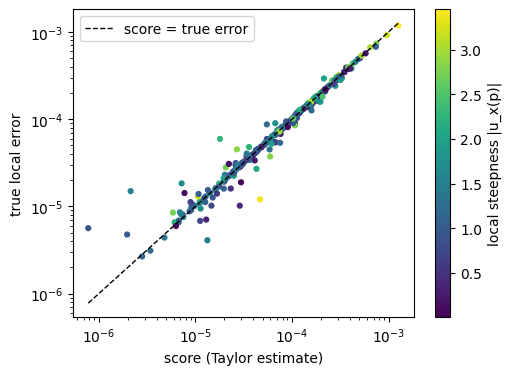

In [28]:
# ── Local error estimate (score): the stencil's error on the local Taylor polynomial of u around p ──
# PDE-specific part: Taylor coefficients with every time derivative replaced using Burgers, u_t = alpha u_xx - u u_x
def taylor_coeffs(d):
    """d = (u, u_x, u_xx, u_xxx, u_xxxx) at p. Returns {(i, j): (d/dx)^i (d/dt)^j u / (i! j!)} for weight i + 2j <= 4."""
    u, u1, u2, u3, u4 = d
    ut   = alpha * u2 - u * u1
    uxt  = alpha * u3 - u * u2 - u1**2                                     # Burgers term: - u_x^2
    uxxt = alpha * u4 - u * u3 - 3 * u1 * u2                               # Burgers term: - 3 u_x u_xx
    utt  = alpha**2 * u4 - 2 * alpha * u * u3 + u**2 * u2 + 2 * u1 * (u * u1 - 2 * alpha * u2)   # Burgers term: 2 u_x (...)
    return {(1, 0): u1, (2, 0): u2 / 2, (3, 0): u3 / 6, (4, 0): u4 / 24,
            (0, 1): ut, (1, 1): uxt, (2, 1): uxxt / 2, (0, 2): utt / 2}

def score(DX, DT, w, d):
    """|sum_q w_q P(dx_q, dt_q)|, P = Taylor polynomial of u around p (without u_p). One stencil (n,) or M stencils (M, n)."""
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d).items())
    return np.abs((w * P).sum(-1))

def x_derivs(f, x, h=2e-3):
    """(u, u_x, u_xx, u_xxx, u_xxxx) of a function f at x, by 7-point central differences."""
    v = f(x + h * np.arange(-3, 4))
    C = [[0, 0, 0, 1, 0, 0, 0], np.array([-1, 9, -45, 0, 45, -9, 1]) / 60, np.array([2, -27, 270, -490, 270, -27, 2]) / 180,
         np.array([1, -8, 13, 0, -13, 8, -1]) / 8, np.array([-1, 12, -39, 56, -39, 12, -1]) / 6]
    return tuple(np.dot(c, v) / h**k for k, c in enumerate(C))

# ── Check: score vs the true local error, for random admissible stencils at random points p anywhere in the domain ──
# here the speed a = u(p) and the derivatives are exact (u_true ONLY for this check); colour = local steepness |u_x|
U = lambda q: u_true(q[0] * dx, q[1] * dt)[0]                       # exact value at one grid point
rng = np.random.default_rng(0)
cells = [(i, j) for j in (-1, -2, -3) for i in range(-3, 4)]               # 3 levels down, |dix| <= 3
S, D, G = [], [], []
while len(S) < 300:
    p = (int(rng.integers(3, nx - 3)), int(rng.integers(3, nt)))          # a random interior point
    nb = [cells[k] for k in rng.choice(len(cells), 5, replace=False)]
    DX, DT = np.array([q[0] for q in nb]) * dx, np.array([q[1] for q in nb]) * dt
    d = x_derivs(lambda x: u_true(x, p[1] * dt), p[0] * dx)
    w = solve_weights(DX, DT, d[0])
    if w is None:
        continue
    u_nb = np.array([U((p[0] + q[0], p[1] + q[1])) for q in nb])
    S.append(score(DX, DT, w, d)); D.append(abs(U(p) - w @ u_nb)); G.append(abs(d[1]))
S, D, G = np.array(S), np.array(D), np.array(G)
print(f"300 admissible stencils, |u_x| from {G.min():.2f} to {G.max():.2f}")
print(f"corr(log score, log true error) = {np.corrcoef(np.log(S), np.log(D))[0, 1]:.2f}, "
      f"median |score - true error| / true error = {np.median(np.abs(S - D) / D):.2f}")

fig, ax = plt.subplots(figsize=(5.5, 4))
sc = ax.scatter(S, D, c=G, s=12, cmap="viridis")
lim = [min(S.min(), D.min()), max(S.max(), D.max())]
ax.loglog(lim, lim, 'k--', lw=1, label='score = true error')
fig.colorbar(sc, label="local steepness |u_x(p)|")
ax.set_xlabel('score (Taylor estimate)'); ax.set_ylabel('true local error'); ax.legend(); plt.show()

### Rough guess of u and its derivatives
To build the map backward, every point needs, before any value has been computed:
- its local speed $a=u$ (for the weights), and
- the space derivatives $u,u_x,\dots,u_{xxxx}$ (for the score, cell 4).

We take them from a cheap **coarse solve**: Lax–Wendroff on a grid 5× coarser, from the initial condition to $T$, computed once for all queries. At each coarse time, a sine series is fitted through the coarse values ($u=0$ at both walls), which gives the derivatives exactly for the fit. In time we interpolate linearly onto our grid.
The guess only steers **which stencils and weights are chosen**. The values at $z^*$ are computed from the neighbours' values, so a poor guess gives worse choices, never wrong numbers. Its cost (840 points) is added to the method's cost.
**Stops.** Two more LW guesses, 2× and 4× coarser still, give an estimate of the guess's own error, $|u-g|\approx|g-g_2|/(R-1)$ with $R$ observed from $g_2$ vs $g_4$ (no exact solution). It is the cost of stopping a point (cell 15).


guesses: 629 + 117 + 30 points (K = 3, 6, 12) | observed R = 2.09
all points   : median relative error for u, u_x, u_xx, u_xxx, u_xxxx: 0.011  0.023  0.036  0.034  0.079
10% steepest : median relative error for u, u_x, u_xx, u_xxx, u_xxxx: 0.003  0.005  0.074  0.050  0.650
stop cost check: estimated / true guess error, median 1.79, corr(log) 0.93


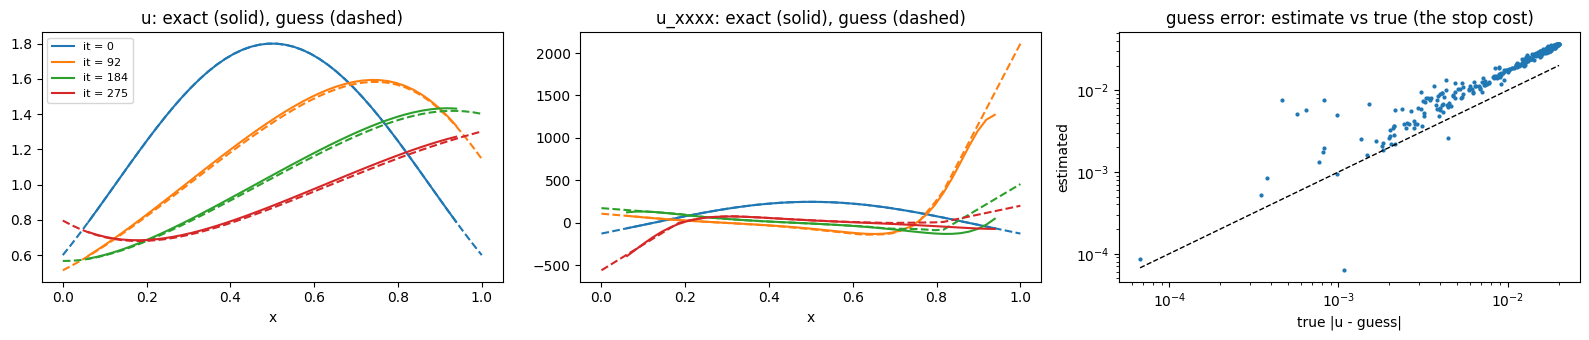

In [29]:
# ── Rough guess of u and its x-derivatives, used ONLY to build the map (speed, weights, score, influence, stops) ──
# Lax-Wendroff on a grid K times coarser, from the initial condition to T, with the same boundary data; computed once.
K_COARSE = {"walls": 5, "inflow_smooth": 3, "inflow_front": 2}[PROBLEM]
from scipy.interpolate import make_interp_spline

def make_guess(K):
    """LW on a grid K times coarser, fitted with a spline in x and linear in t onto our grid.
    Returns GUESS[k, it, ix] (k-th x-derivative at grid point (ix, it)), its cost in grid points, the coarse x and dt."""
    xc  = np.linspace(0.0, 1.0, (nx - 1) // K + 1)
    hc  = xc[1] - xc[0]
    c2, c1 = (A_MAX / hc)**2, 2 * alpha / hc**2                                   # same stability rule as the main grid
    tau = T / int(np.ceil(T / ((-c1 + np.sqrt(c1**2 + 4 * c2 * 0.9)) / (2 * c2))))
    tc  = np.arange(0.0, T + tau / 2, tau)
    Uc  = [u0(xc)]
    for j in range(1, len(tc)):
        u, ui = Uc[-1], Uc[-1][1:-1]
        r, nu = alpha * tau / hc**2, a(ui) * tau / hc
        n = u.copy()
        n[1:-1] = ui + (r + nu**2 / 2) * (u[2:] - 2 * ui + u[:-2]) - nu / 2 * (u[2:] - u[:-2])
        n[0], n[-1] = g_left(tc[j]), g_right(tc[j])                               # boundary data
        Uc.append(n)
    Dc = np.zeros((5, len(tc), nx))                                               # (derivative order, coarse time, our x)
    for j, u in enumerate(Uc):
        sp = make_interp_spline(xc, u, k=min(5, len(xc) - 1))                     # quintic (lower on very coarse grids)
        for k in range(5):
            Dc[k, j] = sp.derivative(k)(x_grid) if k else sp(x_grid)
    tg = np.arange(nt) * dt
    jj = np.minimum((tg // tau).astype(int), len(tc) - 2)
    f  = ((tg - tc[jj]) / tau)[None, :, None]
    return (1 - f) * Dc[:, jj] + f * Dc[:, jj + 1], len(xc) * len(tc), xc, tau

GUESS, G_COARSE, xc, tau = make_guess(K_COARSE)
guess_derivs = lambda q: GUESS[:, q[1], q[0]]                                     # (u, u_x, u_xx, u_xxx, u_xxxx) at q
guess_value  = lambda q: GUESS[0, q[1], q[0]]                                     # the value a stopped point takes

# ── Error of the guess value, for the stop (no u_true): two more guesses, 2x and 4x coarser still ──
#   LW is 2nd order: u - g ~ (g - g2) / (R - 1), R = how much the error grows per halving, observed from g2 vs g4
GUESS2, G_COARSE2, _, _ = make_guess(2 * K_COARSE)
GUESS4, G_COARSE4, _, _ = make_guess(4 * K_COARSE)
_d12, _d24 = np.abs(GUESS[0] - GUESS2[0])[1:, 1:-1], np.abs(GUESS2[0] - GUESS4[0])[1:, 1:-1]
R_OBS = float(np.median(_d24) / np.median(_d12))
guess_err = lambda q: abs(GUESS[0, q[1], q[0]] - GUESS2[0, q[1], q[0]]) / (R_OBS - 1)

# ── Checks: guess vs exact at 300 random points (u_true ONLY for these checks) ──
print(f"guesses: {G_COARSE} + {G_COARSE2} + {G_COARSE4} points (K = {K_COARSE}, {2 * K_COARSE}, {4 * K_COARSE}) | observed R = {R_OBS:.2f}")
rng = np.random.default_rng(0)
pts = [(int(rng.integers(3, nx - 3)), int(rng.integers(1, nt))) for _ in range(300)]
ex  = np.array([x_derivs(lambda x: u_true(x, q[1] * dt), q[0] * dx) for q in pts])
gs  = np.array([guess_derivs(q) for q in pts])
rel = np.abs(gs - ex) / (np.abs(ex) + 1e-12)
steep = np.abs(ex[:, 1]) >= np.quantile(np.abs(ex[:, 1]), 0.9)
for name, sel in [("all points", slice(None)), ("10% steepest", steep)]:
    print(f"{name:13s}: median relative error for u, u_x, u_xx, u_xxx, u_xxxx: " + "  ".join(f"{v:.3f}" for v in np.median(rel[sel], axis=0)))
true_err = np.abs(gs[:, 0] - ex[:, 0])
est_err  = np.array([guess_err(q) for q in pts])
print(f"stop cost check: estimated / true guess error, median {np.median(est_err / true_err):.2f}, "
      f"corr(log) {np.corrcoef(np.log(est_err + 1e-15), np.log(true_err + 1e-15))[0, 1]:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(16, 3.5))
for i, it in enumerate([0, nt // 3, 2 * nt // 3, nt - 1]):
    ex_ = np.array([x_derivs(lambda x: u_true(x, it * dt), xx) for xx in x_grid[3:-3]])
    for ax, k in zip(axes[:2], [0, 4]):
        ax.plot(x_grid[3:-3], ex_[:, k], color=f"C{i}", label=f"it = {it}")
        ax.plot(x_grid, GUESS[k, it], "--", color=f"C{i}")
axes[0].set_title("u: exact (solid), guess (dashed)"); axes[1].set_title("u_xxxx: exact (solid), guess (dashed)")
axes[2].loglog(true_err, est_err, ".", ms=4); lim = [true_err.min(), true_err.max()]
axes[2].loglog(lim, lim, "k--", lw=1); axes[2].set_xlabel("true |u - guess|"); axes[2].set_ylabel("estimated")
axes[2].set_title("guess error: estimate vs true (the stop cost)")
for ax in axes[:2]: ax.set_xlabel("x")
axes[0].legend(fontsize=8); plt.tight_layout(); plt.show()


### Backward map and influence β
**The map.** Start at $z^*$ and give it a stencil. Each neighbour that is not known data (IC or wall) becomes a new point that also needs a stencil. Repeat until every branch ends on the IC or a wall. Points are expanded **latest $t$ first**.

**Weights.** No values exist yet while building, so each point $p$ takes its speed from the guess (cell 5), $a_p=u_{\rm guess}(p)$, rounded to steps of 0.02 so the weights can be cached by (shape, speed). Its score uses the guessed derivatives at $p$ (cell 4).

**Influence.** $\beta_p$ = how much an error at $p$ changes the value at $z^*$. Start with $\beta_{z^*}=1$. When $p$ is expanded with weights $w$, pass its influence down: $\beta_q \mathrel{+}= \beta_p\,w_q$.

**Forward pass.** Values are computed bottom-up from the IC and walls, $\hat u_p=\sum_q w_q\hat u_q$, **with the weights chosen in the map**. Recomputing them with another speed would undo the choice: the score was computed for exactly these weights. The guess shapes the stencils and weights, but no guessed value enters $\hat u$.

**Exact identity.** With $\delta_p=u_p-\sum_q w_qu_q$ the local error,
$$e(z^*)=\sum_p\beta_p\,\delta_p .$$
Check: give every point the Lax–Wendroff stencil; the identity must hold to all digits.
**Stops.** A point may take no stencil and use the guess value instead (`choose` returns `None`). It is then a leaf like the IC, and its error is the guess error: $e(z^*)=\sum_{\rm expanded}\beta_p\delta_p+\sum_{\rm stopped}\beta_p(u_p-g_p)$, still exact.
**Forward pass: 3 Picard steps** (the speed of each point re-solved from its own value 3 times; 1 step left it half-way, 3 steps halve the error of the maps for free).


In [30]:
# ── Known data: the initial condition and the walls are given, not computed ──
# their values are the exact solution there: u0 at t = 0, the boundary data g_left / g_right on the walls
is_known    = lambda q: q[1] == 0 or q[0] in (0, nx - 1)
known_value = Ug

# ── Speed at p for its weights: from the guess, rounded to A_STEP so weights can be cached ──
A_STEP  = 0.02
a_build = lambda p: A_STEP * round(a(guess_derivs(p)[0]) / A_STEP)

_w_cache = {}
def weights(p, nbs):
    """Taylor weights of p's neighbours nbs (grid points), with p's guessed speed; None if not admissible.
    Cached by (shape, speed). Solved with the neighbours sorted (latest level first, then left to right), so the
    result never depends on the order the neighbours were picked in."""
    order = sorted(range(len(nbs)), key=lambda i: (-nbs[i][1], nbs[i][0]))
    offs  = tuple((nbs[i][0] - p[0], nbs[i][1] - p[1]) for i in order)
    key   = (offs, a_build(p))
    if key not in _w_cache:
        _w_cache[key] = solve_weights(np.array([o[0] for o in offs]) * dx, np.array([o[1] for o in offs]) * dt, key[1])
    if _w_cache[key] is None:
        return None
    w = np.empty(len(nbs)); w[order] = _w_cache[key]                  # back to the order of nbs
    return w

def point_score(p, nbs, w):
    """Estimated local error of p's stencil, with the guessed derivatives at p."""
    return score(np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt, w, guess_derivs(p))
# ── Same-level neighbours (upwind only) ──
#   SAME_LEVEL = k > 0 adds the cells (-1, 0) .. (-k, 0): neighbours on p's OWN time level, to its left (upwind for u > 0).
#   To stay explicit (no linear solve): within a level, values are computed LEFT to right (left neighbours are ready),
#   and points are expanded RIGHT to left (every user of a point has passed its influence down before the point is
#   expanded, so beta stays exact). SAME_LEVEL = 0 restores the original window and order (needed for the old agents).
SAME_LEVEL = 0
ORDER = -1 if SAME_LEVEL else 1                      # sign of ix in the pending heap: -1 = right to left within a level

# ── The map, built backward from z* ──
# Points wait in `pending` and are expanded LATEST t first (and, within a level, in the order above): every point that can
# use p is expanded before p, so p's influence beta_p is complete when p is expanded.
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], ORDER * z_star[0])], "beta": {z_star: 1.0}, "stencil": {}}

def pending_points(m):
    """The pending points as (ix, it)."""
    return [(ORDER * k, -it) for it, k in m["pending"]]
# ── Same-level neighbours on BOTH sides ──
#   SAME_LEVEL = k > 0 adds the cells (-k..-1, 0) and (1..k, 0): neighbours on p's own time level, left AND right.
#   No linear solve: within a level the same-level links must form no cycle (a mask forbids any link that would close one),
#   so the level can be computed in dependency order. Because a point's same-level users can come after it, its influence
#   beta is only final when its whole level is done: beta is passed down ONE LEVEL AT A TIME, when the level is complete.
#   SAME_LEVEL = 0 gives back the original window (needed for the old agents).

# ── The map, built backward from z* ──
# Points wait in `pending` and are expanded latest t first, left to right within a level. Stencils are chosen point by
# point; when the last point of a level is expanded, the level is "closed": its beta is passed down (users before the
# points they use), which completes the beta of the lower points before they are expanded.
def start_map(z_star):
    return {"z_star": z_star, "pending": [(-z_star[1], z_star[0])], "beta": {z_star: 1.0}, "stencil": {},
            "same": {}, "level": [], "stopped": set()}   # same: p -> same-level points p uses | level: expanded points of the open level
                                              # stopped: points that take the guess value

def next_point(m):
    it, ix = m["pending"][0]
    return (ix, -it)

def reaches(m, a, b):
    """True if same-level point a uses b, directly or through other same-level points."""
    stack, seen = [a], set()
    while stack:
        q = stack.pop()
        if q == b:
            return True
        if q not in seen:
            seen.add(q); stack.extend(m["same"].get(q, []))
    return False

def forbidden(m, p):
    """Window cells p may not use: same-level points that already use p (directly or not), which would close a cycle."""
    return [k for k in range(N_CELLS) if WINDOW[k][1] == 0 and not is_known(place(p, k)) and reaches(m, place(p, k), p)]

def users_first(m, pts):
    """The points of one level ordered so that every point comes before the same-level points it uses."""
    pts, order, done = set(pts), [], set()
    def visit(q):                                  # depth-first: a point is placed after all its same-level users
        if q in done:
            return
        done.add(q)
        for r in pts:
            if q in m["same"].get(r, []):
                visit(r)
        order.append(q)
    for q in sorted(pts):
        visit(q)
    return order

def close_level(m):
    """Pass the open level's beta down (users first) and return the level's points (their beta is now final)."""
    pts = m["level"]
    for p in users_first(m, pts):
        nbs, w = m["stencil"][p]
        for q, wq in zip(nbs, w):
            if not is_known(q):
                m["beta"][q] += m["beta"][p] * wq
    m["level"] = []
    return pts

def expand(m, nbs):
    """Give the next point the stencil nbs. Returns (p, w, closed): closed = the points whose beta became final now."""
    it, ix = heapq.heappop(m["pending"])
    p = (ix, -it)
    w = weights(p, nbs)
    m["stencil"][p] = (nbs, w)
    m["same"][p] = [q for q in nbs if q[1] == p[1] and not is_known(q)]
    for q in nbs:
        if not is_known(q) and q not in m["beta"]:
            m["beta"][q] = 0.0
            heapq.heappush(m["pending"], (-q[1], q[0]))
    m["level"].append(p)
    level_done = not m["pending"] or m["pending"][0][0] != it
    return p, w, (close_level(m) if level_done else [])

def stop_point(m):
    """Stop the next point: no stencil, it takes the guess value (a leaf, like the IC). Returns the points whose beta became
    final if this was the last point of its level (as expand does)."""
    it, ix = heapq.heappop(m["pending"])
    m["stopped"].add((ix, -it))
    level_done = not m["pending"] or m["pending"][0][0] != it
    return close_level(m) if level_done and m["level"] else []

def build_map(z_star, choose):
    """Whole map; choose(m, p) returns the neighbours of p (it must respect forbidden(m, p)), or None to stop p."""
    m = start_map(z_star)
    while m["pending"]:
        nbs = choose(m, next_point(m))
        stop_point(m) if nbs is None else expand(m, nbs)
    return m

# ── Forward pass: values bottom-up; within a level, every point after the same-level points it uses ──
# The map fixes the neighbours (chosen with the guessed speed). Each point then re-solves its weights with the speed
# of its own computed value (picard steps; 0 = keep the map's weights), so the guessed speed never enters the values.
# 3 steps: one step left the speed half-way (it came from a value computed with the guessed-speed weights).
# Stopped points take the guess value.
# The weights actually used are kept in m["w_used"] (report needs them).
def forward_order(m):
    order = []
    for t in sorted({p[1] for p in m["stencil"]}):
        order += users_first(m, [p for p in m["stencil"] if p[1] == t])[::-1]
    return order

def evaluate(m, picard=3):
    u_hat, m["w_used"] = {q: guess_value(q) for q in m["stopped"]}, {}
    value = lambda q: known_value(q) if is_known(q) else u_hat[q]
    for p in forward_order(m):
        nbs, w = m["stencil"][p]
        v = np.array([value(q) for q in nbs])
        DX, DT = np.array([q[0] - p[0] for q in nbs]) * dx, np.array([q[1] - p[1] for q in nbs]) * dt
        for _ in range(picard):
            w_new = solve_weights(DX, DT, a(w @ v))             # speed from the value just computed
            if w_new is None:                                   # not admissible: keep the last weights
                break
            w = w_new
        m["w_used"][p], u_hat[p] = w, w @ v
    return u_hat
# ── Check: every point takes the Lax-Wendroff stencil (3 points one level down) ──
# z* = (20, 40) is close enough to the left wall that its cone reaches it: the wall data is used.
# The identity only holds if the known data (IC and walls) is exact.
lw = lambda m, p: [(p[0] - 1, p[1] - 1), (p[0], p[1] - 1), (p[0] + 1, p[1] - 1)]
z = (10, 40)
m = build_map(z, lw)
err = Ug(z) - evaluate(m, picard=0)[z]                       # the map's own weights: the identity must hold exactly
delta = {p: Ug(p) - w @ np.array([Ug(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
n_wall = sum(1 for p, (nbs, w) in m["stencil"].items() for q in nbs if q[0] in (0, nx - 1) and q[1] > 0)
print(f"LW map at z* = {z}: {len(m['stencil'])} points, {n_wall} uses of wall data | error at z* {abs(err):.2e}")
print(f"identity: e(z*) = {err:.6e}, sum beta*delta = {sum(m['beta'][p] * delta[p] for p in delta):.6e}")
print(f"with live speed (3 Picard steps): error at z* {abs(Ug(z) - evaluate(m)[z]):.2e}")

# ── Check: stops (points with |beta| < 1e-3 take the guess value); the identity must still hold exactly ──
m = build_map(z, lambda m, p: None if abs(m["beta"][p]) < 1e-3 else lw(m, p))
err = Ug(z) - evaluate(m, picard=0)[z]
delta = {p: Ug(p) - w @ np.array([Ug(q) for q in nbs]) for p, (nbs, w) in m["stencil"].items()}
delta.update({q: Ug(q) - guess_value(q) for q in m["stopped"]})          # a stopped point's error is its guess error
print(f"LW map + stops at z* = {z}: {len(m['stencil'])} points, {len(m['stopped'])} stops | "
      f"identity: e(z*) = {err:.6e}, sum beta*delta = {sum(m['beta'][p] * delta[p] for p in delta):.6e}")

LW map at z* = (10, 40): 1134 points, 31 uses of wall data | error at z* 6.66e-04
identity: e(z*) = -6.657830e-04, sum beta*delta = -6.657830e-04
with live speed (3 Picard steps): error at z* 2.91e-04
LW map + stops at z* = (10, 40): 660 points, 30 stops | identity: e(z*) = -5.698898e-04, sum beta*delta = -5.698898e-04


### Window, admissible stencils and the mask
**Window.** The candidate neighbours of $p$ are the 21 cells up to 3 to each side and 1 to 3 levels below $p$. A cell past a wall or below $t=0$ is moved onto the wall or the IC (known data).
**Admissible stencils.** Every choice of 5 cells whose weights pass the admissibility test (cell 3), with $p$'s guessed speed. Points with the same local situation (distance to walls/IC) and the same guessed speed share one list, computed once and cached together with each stencil's **moments** $\sum_q w_q\Delta x_q^i\Delta t_q^j$. The score at a point is then just these moments times the Taylor coefficients at that point (cell 4): one small product per point.
**Mask.** The agent will pick the 5 cells one at a time. A cell may be picked next only if some admissible stencil contains it together with the picks so far, so the agent can never end up with a bad stencil.
**First rule without RL:** every point takes its lowest-score stencil. **Report** gives a finished map's points, its true error at $z^*$ and its exact bound $\sum_p|\beta_p\delta_p|$ (exact solution used only for reporting).

21 window cells | interior point (25, 40): 18768 admissible stencils of 20349
first pick allowed on 21 cells
LW          : 1344 points, error 5.29e-04, exact bound 5.52e-04  (0 s)
lowest score: 1536 points, error 3.95e-05, exact bound 4.69e-04  (13 s)


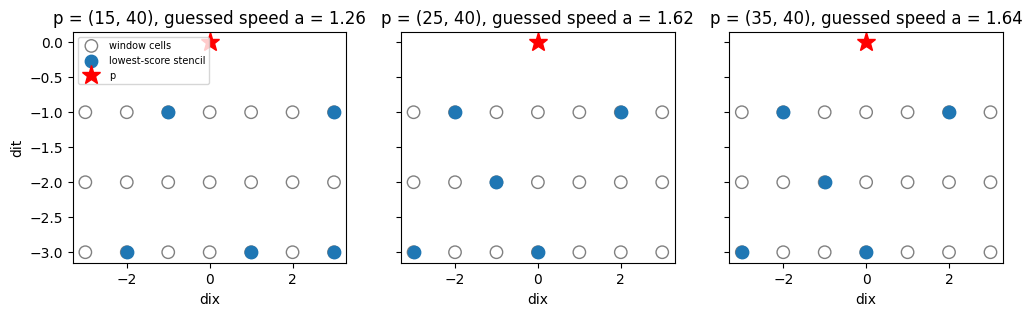

In [31]:
# ── The window: candidate neighbour cells below p ──
R_X, K_T = 3, 3                       # |dix| <= 3 cells, 1 to 3 levels down
WINDOW  = ([(k, 0) for k in list(range(-SAME_LEVEL, 0)) + list(range(1, SAME_LEVEL + 1))]
           + [(dix, dit) for dit in range(-1, -K_T - 1, -1) for dix in range(-R_X, R_X + 1)])
N_CELLS = len(WINDOW)
N_NB    = 5                           # neighbours per stencil
TERMS   = list(taylor_coeffs((0.0,) * 5))                             # the (i, j) Taylor terms of the score

def place(p, k):
    """Grid point of window cell k seen from p. Past a wall or below t = 0 -> moved onto it."""
    return (min(max(p[0] + WINDOW[k][0], 0), nx - 1), max(p[1] + WINDOW[k][1], 0))

# ── Every admissible stencil at p ──
# Cached by p's local situation and guessed speed: the stencils, which cells they use, and their moments
# sum_q w_q dx^i dt^j for each Taylor term. The score at p is then |moments @ Taylor coefficients at p|.
_sets_cache = {}
def admissible(p):
    """(stencils as tuples of cells, cell-usage matrix, scores at p). Cells that land on the same point count once."""
    key = (tuple((place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)), a_build(p))
    if key not in _sets_cache:
        cells, seen = [], set()
        for k in range(N_CELLS):
            if place(p, k) not in seen:
                seen.add(place(p, k)); cells.append(k)
        sets = list(itertools.combinations(cells, min(N_NB, len(cells))))
        off  = np.array([[(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in s] for s in sets])   # (M, n, 2)
        DX, DT = off[..., 0] * dx, off[..., 1] * dt
        W, ok  = solve_weights_many(DX, DT, a_build(p))                # all candidate stencils in one solve
        sets   = [s for s, o in zip(sets, ok) if o]
        mom    = np.stack([(W[ok] * DX[ok]**i * DT[ok]**j).sum(1) for i, j in TERMS], axis=1)
        uses   = np.zeros((len(sets), N_CELLS), dtype=bool)
        for i, s in enumerate(sets):
            uses[i, list(s)] = True
        _sets_cache[key] = (sets, uses, mom)
    sets, uses, mom = _sets_cache[key]
    c = taylor_coeffs(guess_derivs(p))
    return sets, uses, np.abs(mom @ np.array([c[t] for t in TERMS]))

def allowed_sets(m, p):
    """Admissible stencils at p that use no forbidden (cycle-closing) cell: (sets, uses, scores) restricted to them.
    Cached on the map for the current point (it only changes when a stencil is placed), so the 5 picks of a point share it."""
    key = (p, len(m["stencil"]))
    if m.get("_allowed_key") != key:
        sets, uses, sc = admissible(p)
        bad = forbidden(m, p)
        ok = ~uses[:, bad].any(axis=1) if bad else np.ones(len(sets), dtype=bool)
        m["_allowed"] = ([s for s, o in zip(sets, ok) if o], uses[ok], sc[ok]) if bad else (sets, uses, sc)
        m["_allowed_key"] = key
    return m["_allowed"]

def pick_mask(m, p, picks):
    """Cell k may be picked next if some allowed stencil contains the picks so far plus k."""
    _, uses, _ = allowed_sets(m, p)
    ok = uses[:, picks].all(axis=1) if picks else np.ones(len(uses), dtype=bool)
    mask = uses[ok].any(axis=0)
    mask[picks] = False
    return mask

def lowest_score(m, p):
    sets, _, sc = allowed_sets(m, p)
    return [place(p, k) for k in sets[int(np.argmin(sc))]]

# ── Report of a finished map: points, true error at z*, exact bound sum |beta delta| (u_true ONLY for reporting) ──
# ── Report of a finished map: points, true error at z*, exact bound sum |beta delta| (u_true ONLY for reporting) ──
# with the weights the forward pass actually used (live speed); beta is recomputed with them, so e(z*) = sum beta delta
def report(m):
    """Points, true error at z*, exact bound sum |beta delta| with the weights the forward pass used (u_true ONLY here)."""
    z = m["z_star"]
    u_hat, W = evaluate(m), m["w_used"]
    beta = {z: 1.0}
    for p in forward_order(m)[::-1]:                              # every user before the points it uses
        for q, wq in zip(m["stencil"][p][0], W[p]):
            if not is_known(q):
                beta[q] = beta.get(q, 0.0) + beta[p] * wq
    delta = {p: Ug(p) - W[p] @ np.array([Ug(q) for q in m["stencil"][p][0]]) for p in m["stencil"]}
    delta.update({q: Ug(q) - guess_value(q) for q in m["stopped"]})       # a stopped point's error is its guess error
    return {"points": len(m["stencil"]), "stops": len(m["stopped"]), "error": abs(Ug(z) - u_hat[z]),
            "bound": sum(abs(beta[p] * delta[p]) for p in delta)}
z = (25, 40)
sets, _, sc = admissible(z)
print(f"{N_CELLS} window cells | interior point {z}: {len(sets)} admissible stencils of "
      f"{len(list(itertools.combinations(range(N_CELLS), N_NB)))}")
print("first pick allowed on", pick_mask(start_map(z), z, []).sum(), "cells")
for name, rule in [("LW", lw), ("lowest score", lowest_score)]:
    t0 = time.time()
    rep = report(build_map(z, rule))
    print(f"{name:12s}: {rep['points']} points, error {rep['error']:.2e}, exact bound {rep['bound']:.2e}  ({time.time() - t0:.0f} s)")

# ── Picture: the lowest-score stencil at three points with different speeds ──
fig, axes = plt.subplots(1, 3, figsize=(12, 3), sharey=True)
for ax, p in zip(axes, [(15, 40), (25, 40), (35, 40)]):
    sets, _, sc = admissible(p)
    best = sets[int(np.argmin(sc))]
    ax.scatter(*np.array(WINDOW).T, s=80, facecolors='none', edgecolors='gray', label='window cells')
    ax.scatter(*np.array([WINDOW[k] for k in best]).T, s=80, color='tab:blue', label='lowest-score stencil')
    ax.plot(0, 0, 'r*', ms=14, label='p')
    ax.set_title(f"p = {p}, guessed speed a = {a_build(p):.2f}"); ax.set_xlabel('dix')
axes[0].set_ylabel('dit'); axes[0].legend(fontsize=7, loc='upper left'); plt.show()

In [32]:
def greedy_rule(lam):
    """At every point the allowed stencil with the best one-step reward (beta_p as known when p is expanded)."""
    def choose(m, p):
        sets, uses, sc = allowed_sets(m, p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

### Environment
**Episode.** Build one map for the query $z^*$. At each step the agent picks one window cell for the current point (the latest-$t$ pending point), or **STOP** (before its first pick, never at $z^*$): the point takes the guess value and creates no new points. After 5 picks the stencil is complete, the point is expanded, and the next point comes up.
**Reward**, for a stencil and for a stop:
$$r_p=-\frac{|\beta_p|\,s_p}{\rm EPS}-\lambda\,\frac{\text{new points}}{N_{\rm LW}},\qquad r_p^{\rm stop}=-\frac{|\beta_p|\,\hat g_p}{\rm EPS},$$
with $s_p$ the score and $\hat g_p$ the estimated guess error (cell 8). No exact solution enters a reward.
**Shaping** (`SHAPING = True`). The saving of a stop (the subtree never built) only shows up hundreds of steps later, so without help the agent never stops. Every reward gets $\Phi(s')-\Phi(s)$ added, with $\Phi=-\sum_{q\ \rm pending}\big(|\beta_q|A_q/{\rm EPS}+\lambda N_q/N_{\rm LW}\big)$: the estimated cost of finishing the pending points, from the LW map of the same $z^*$ ($A_q$: its score per unit influence, $N_q$: its points). A stop removes $q$'s future cost at once, so it is paid for at once. Over an episode the extra terms add up to $-\Phi(s_0)$, a constant of the query, so the best policy does not change (potential-based shaping).
**State**: as before (picked / in the map / known data per window cell, $\log|\beta_p|$, position, guessed $u,u_x,u_{xx}$, workload, $\log\lambda$) plus the cost of stopping $p$ now.


In [33]:
# ── Units of the reward ──
#   accuracy: the estimated error share |beta_p| s_p, in units of EPS (a fixed target error for the problem, same for every query)
#   cost:     new points, in units of N_LW (the point count of the Lax-Wendroff map of the same z*: "a classical solve")
EPS = {"walls": 1e-5, "inflow_smooth": 1e-3, "inflow_front": 1e-4}[PROBLEM]
_nlw_cache = {}
def n_lw(z):
    """Points of the LW map of z* (the cost unit)."""
    if z not in _nlw_cache:
        _nlw_cache[z] = len(build_map(z, lw)["stencil"])
    return _nlw_cache[z]

# ── State switch: per-cell physics features (off: they made training unstable) ──
STATE_X = False
def cell_features(p):
    d, ap = guess_derivs(p), a_build(p)
    off = np.array([(place(p, k)[0] - p[0], place(p, k)[1] - p[1]) for k in range(N_CELLS)], dtype=float)
    DX, DT = off[:, 0] * dx, off[:, 1] * dt
    xi = DX - ap * DT
    P = sum(c * DX**i * DT**j for (i, j), c in taylor_coeffs(d).items())
    R = P - d[1] * xi - d[2] * (0.5 * xi**2 + alpha * DT)
    return np.concatenate([xi / dx, np.sign(R) * np.log10(1 + np.abs(R) / dx**3)])

# ── Shaping potential: the cost-to-go of every point of the LW map of z* (estimates only: score, beta, no u_true) ──
#   A_q = s_q + sum_r |w_r| A_r : estimated error of q's subtree per unit influence
#   N_q = 1 + sum_r N_r / users(r) : points of q's subtree (a point shared by several users is split between them)
def cost_to_go(m):
    users = {}
    for p, (nbs, w) in m["stencil"].items():
        for q in set(nbs):
            users[q] = users.get(q, 0) + 1
    A, N = {}, {}
    for p in forward_order(m):                                    # bottom-up: the points a stencil uses come first
        nbs, w = m["stencil"][p]
        A[p], N[p] = point_score(p, nbs, w), 1.0
        for q, wq in zip(nbs, w):
            if q in A:                                            # an expanded point (not data)
                A[p] += abs(wq) * A[q]
                N[p] += N[q] / users[q]
    return A, N

_ctg_cache = {}
def lw_cost_to_go(z):
    if z not in _ctg_cache:
        _ctg_cache[z] = cost_to_go(build_map(z, lw))
    return _ctg_cache[z]

# ── Environment: one step = one pick, or STOP; a reward each time a stencil is complete or a point is stopped ──
#   stencil at p:  -|beta_p| s_p / EPS  -  lam * (new points) / N_LW
#   stop at p:     -|beta_p| g_err(p) / EPS          (p takes the guess value: its error is the guess error; no new points)
#   SHAPING = True adds Phi(after) - Phi(before) to every reward, Phi = -(estimated cost of finishing the pending points,
#   from the LW map's cost-to-go). A stop then gets the credit for the subtree it saves at once, not hundreds of steps later.
#   Over an episode the extra terms add up to -Phi(start), a constant of the query: the best policy does not change.
#   lam (the price of a point) is drawn per episode, log-uniform in lam_range, and shown to the agent
SHAPING = False
L_SCALE = 0.1                                                     # length scale that makes u_x, u_xx of order 1
STOP    = N_CELLS                                                 # the extra action
N_OBS   = 3 * N_CELLS + 13 + (2 * N_CELLS if STATE_X else 0)

class MapEnv(gym.Env):
    def __init__(self, queries, lam_range=(0.1, 10.0), cap=3.0, shaping=None):
        super().__init__()
        self.queries, self.lam_range, self.cap = queries, lam_range, cap
        self.shaping = SHAPING if shaping is None else shaping
        self.observation_space = spaces.Box(-np.inf, np.inf, shape=(N_OBS,), dtype=np.float32)
        self.action_space = spaces.Discrete(N_CELLS + 1)            # one action = one window cell, or STOP

    def reset(self, seed=None, options=None):
        super().reset(seed=seed)
        self.z   = self.queries[self.np_random.integers(len(self.queries))]
        self.lam = float(np.exp(self.np_random.uniform(*np.log(self.lam_range))))
        self.N_ref = n_lw(self.z)
        self.m, self.picks, self.B = start_map(self.z), [], 0.0
        self.phi = self._phi()
        self._play_forced()
        self.phi = self._phi()                                    # forced points are not the agent's doing
        return self._obs(), {}

    def _phi(self):
        """Shaping potential: minus the estimated cost of finishing every pending point (0 without shaping)."""
        if not self.shaping:
            return 0.0
        A, N = lw_cost_to_go(self.z)
        return -sum(abs(self.m["beta"][q]) * A.get(q, 0.0) / EPS + self.lam * N.get(q, 1.0) / self.N_ref
                    for q in pending_points(self.m))

    def _complete(self, cells):
        """Expand the next point with these cells. Reward: the points' cost now; the accuracy terms of a level when it closes."""
        p = next_point(self.m)
        nbs = [place(p, k) for k in cells]
        n_new = sum(1 for q in set(nbs) if not is_known(q) and q not in self.m["beta"])
        _, _, closed = expand(self.m, nbs)
        return -self._accuracy(closed) - self.lam * n_new / self.N_ref

    def _stop(self):
        """Stop the next point. Reward: its guess error times its influence (and the level's accuracy if it closes)."""
        p = next_point(self.m)
        cost = abs(self.m["beta"][p]) * guess_err(p)
        self.B += cost
        return -cost / EPS - self._accuracy(stop_point(self.m))

    def _accuracy(self, pts):
        """Sum of |beta_p| s_p / EPS over points whose beta is final."""
        term = sum(abs(self.m["beta"][q]) * point_score(q, *self.m["stencil"][q]) for q in pts)
        self.B += term
        return term / EPS

    def _play_forced(self):
        """Points with only one allowed stencil need no decision."""
        r = 0.0
        while self.m["pending"]:
            sets, _, _ = allowed_sets(self.m, next_point(self.m))
            if len(sets) != 1:
                break
            r += self._complete(sets[0])
        return r

    def _obs(self):
        if not self.m["pending"]:
            return np.zeros(N_OBS, np.float32)
        p = next_point(self.m)
        pts    = [place(p, k) for k in range(N_CELLS)]
        picked = np.zeros(N_CELLS); picked[self.picks] = 1
        exists = np.array([q in self.m["beta"] for q in pts])            # reusing it creates no new point
        known  = np.array([is_known(q) for q in pts])                    # IC or wall: exact, the branch ends there
        pend   = pending_points(self.m)
        d      = guess_derivs(p)
        glob = [np.log10(abs(self.m["beta"][p]) + 1e-12),          # influence of p on z*
                p[1] / self.z[1],                                  # height above the IC, as a fraction of z*'s
                (p[0] - self.z[0]) / nx,                           # offset to z* in x
                p[0] / nx, (nx - 1 - p[0]) / nx,                   # distance to the left and right wall
                d[0], d[1] * L_SCALE, d[2] * L_SCALE**2,           # local solution (guess): speed, slope, curvature
                len(self.m["stencil"]) / self.N_ref,               # points used so far
                len(pend) / self.N_ref,                            # points still waiting for a stencil
                sum(abs(self.m["beta"][q]) for q in pend),         # their total influence
                np.log10(self.lam),                                # price of a point
                np.log10(abs(self.m["beta"][p]) * guess_err(p) / EPS + 1e-12)]   # what stopping p would cost now
        feats = [cell_features(p)] if STATE_X else []
        return np.concatenate([picked, exists, known, glob] + feats).astype(np.float32)

    def step(self, k):
        if k == STOP:
            r = self._stop()
        else:
            self.picks.append(int(k))
            if len(self.picks) < len(allowed_sets(self.m, next_point(self.m))[0][0]):   # still choosing p's stencil
                return self._obs(), 0.0, False, False, {}
            r = self._complete(self.picks)
            self.picks = []
        r += self._play_forced()
        n = len(self.m["stencil"]) + len(self.m["pending"])
        if self.m["pending"] and n <= self.cap * self.N_ref:       # map not finished
            phi = self._phi()
            r, self.phi = r + phi - self.phi, phi
            return self._obs(), r, False, False, {}
        # finished, or over the point cap: close the open level, then each point left unexpanded costs its worst stencil
        r -= self._accuracy(close_level(self.m)) if self.m["level"] else 0.0
        for q in pending_points(self.m):
            r -= abs(self.m["beta"][q]) * admissible(q)[2].max() / EPS
        r -= self.phi                                              # Phi = 0 at the end
        info = {"finished": not self.m["pending"], "points": len(self.m["stencil"]), "lam": self.lam,
                "stops": len(self.m["stopped"]), "score_ratio": self.B / EPS, "points_ratio": len(self.m["stencil"]) / self.N_ref}
        return np.zeros(N_OBS, np.float32), r, True, False, info

    def action_masks(self):
        p = next_point(self.m)
        return np.r_[pick_mask(self.m, p, self.picks), not self.picks and p != self.z]   # STOP: before the first pick, never z*

# ── Check: one episode with random (masked) picks, with and without shaping, on the same picks ──
#   without shaping the rewards add up to the return formula; with shaping they differ from it by exactly -Phi(start)
#   (a point that is created and later stopped was paid for when it was created: it counts in the points term)
for shaping in (False, True):
    env = MapEnv(queries=[(25, 40)], lam_range=(1.0, 1.0), shaping=shaping)
    obs, _ = env.reset(seed=0)
    phi0 = env.phi
    rng, total, steps, done = np.random.default_rng(0), 0.0, 0, False
    while not done:
        obs, r, done, _, info = env.step(rng.choice(np.flatnonzero(env.action_masks())))
        total += r; steps += 1
    formula = -info["score_ratio"] - info["lam"] * (info["points"] + info["stops"] - 1) / env.N_ref
    print(f"shaping {shaping!s:5s}: obs size {N_OBS} | {steps} steps | {info['points']} points, {info['stops']} stops | "
          f"sum of rewards {total:.4f} | -B/EPS - lam (points + stops - 1)/N_LW = {formula:.4f} | difference {total - formula:.4f}"
          + (f" (should be -Phi(start) = {-phi0:.4f})" if shaping else " (should be 0)"))


shaping False: obs size 76 | 7156 steps | 1414 points, 96 stops | sum of rewards -10.1714 | -B/EPS - lam (points + stops - 1)/N_LW = -10.1714 | difference 0.0000 (should be 0)
shaping True : obs size 76 | 7156 steps | 1414 points, 96 stops | sum of rewards -8.4549 | -B/EPS - lam (points + stops - 1)/N_LW = -10.1714 | difference 1.7165 (should be -Phi(start) = 1.7165)


### Map figure
One figure for any finished map, used for the baselines and the training videos:
1. the map, coloured by influence $|\beta_p|$ on $z^*$;
2. a zoom on $z^*$ with the stencils of the top levels;
3. the accumulated error $|\hat u_p-u_p|$ at every computed point;
4. the error share $|\beta_p\delta_p|$ of every point (these add up to the exact bound).

Panels 3 and 4 use the exact solution, only for this figure.

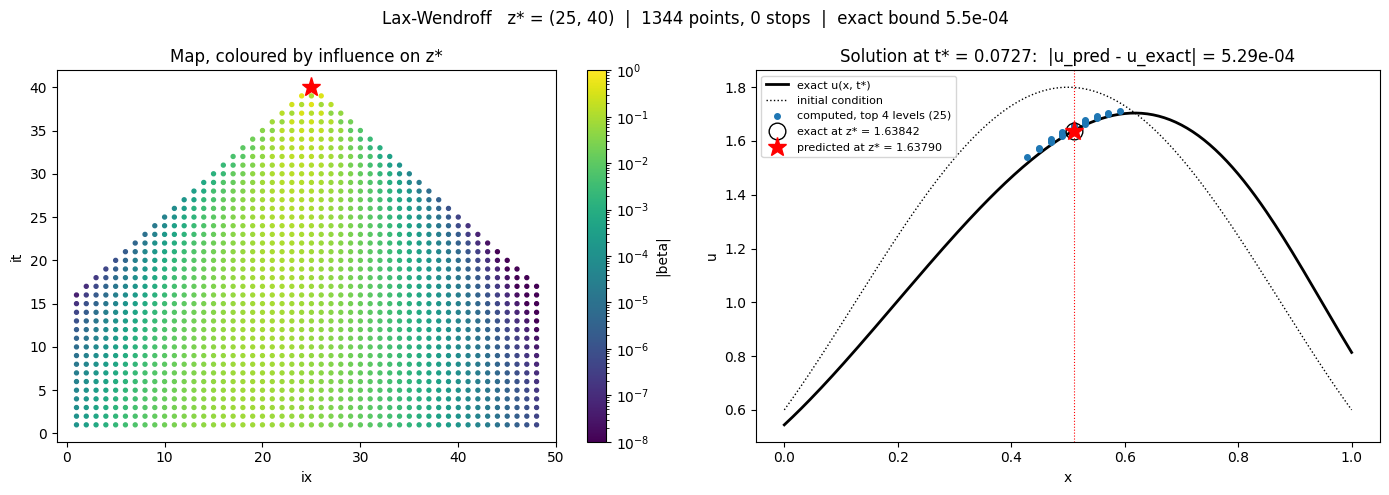

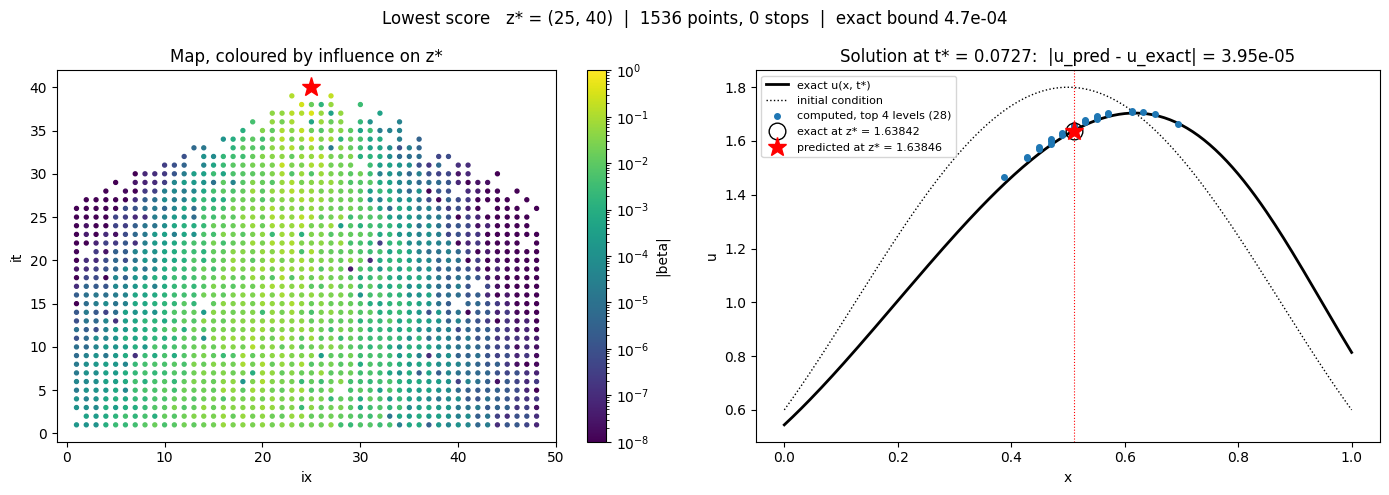

In [34]:
# ── One figure for any finished map (used for the baselines and the training videos) ──
#   left : the map, coloured by influence |beta| on z*
#   right: the solution at t*: exact u(x, t*), the computed points of the top levels, and the value at z* (u_true ONLY here)
from matplotlib.colors import LogNorm

def plot_map(m, title="", path=None, top=4):
    z, rep = m["z_star"], report(m)
    u_hat = evaluate(m)
    P = np.array(list(m["stencil"]))
    fig, (a1, a2) = plt.subplots(1, 2, figsize=(14, 5))

    sc = a1.scatter(P[:, 0], P[:, 1], c=[abs(m["beta"][tuple(p)]) for p in P], s=8, cmap="viridis", norm=LogNorm(1e-8, 1))
    if m["stopped"]:
        S = np.array(list(m["stopped"]))
        a1.plot(S[:, 0], S[:, 1], "x", color="#e34948", ms=4, label=f"stopped ({len(S)})"); a1.legend(fontsize=8)
    a1.plot(*z, "r*", ms=14)
    fig.colorbar(sc, ax=a1, label="|beta|")
    a1.set_xlim(-1, nx); a1.set_xlabel("ix"); a1.set_ylabel("it"); a1.set_title("Map, coloured by influence on z*")

    xf = np.linspace(0, 1, 201)
    a2.plot(xf, u_true(xf, z[1] * dt), "k-", lw=2, label="exact u(x, t*)")
    a2.plot(xf, u0(xf), "k:", lw=1, label="initial condition")
    near = [p for p in u_hat if p[1] >= z[1] - top]
    a2.plot([p[0] * dx for p in near], [u_hat[p] for p in near], "o", color="C0", ms=4,
            label=f"computed, top {top} levels ({len(near)})")
    a2.plot(z[0] * dx, Ug(z), "ko", ms=12, mfc="none", label=f"exact at z* = {Ug(z):.5f}")
    a2.plot(z[0] * dx, u_hat[z], "r*", ms=14, label=f"predicted at z* = {u_hat[z]:.5f}")
    a2.axvline(z[0] * dx, color="r", ls=":", lw=0.8)
    a2.set_xlabel("x"); a2.set_ylabel("u"); a2.legend(fontsize=8)
    a2.set_title(f"Solution at t* = {z[1] * dt:.4f}:  |u_pred - u_exact| = {rep['error']:.2e}")

    fig.suptitle(f"{title}   z* = {z}  |  {rep['points']} points, {rep['stops']} stops  |  exact bound {rep['bound']:.1e}")
    plt.tight_layout()
    if path:
        fig.savefig(path, dpi=100, bbox_inches="tight"); plt.close(fig)
    else:
        plt.show()

plot_map(build_map((25 , 40), lw), "Lax-Wendroff")
plot_map(build_map((25, 40), lowest_score), "Lowest score")

### Training helpers and callbacks
- `make_env`: one training environment (with the action mask and the episode monitor).
- `run_policy`: one episode where the policy takes its most likely pick every time; returns the finished map.
- `MapLogCallback`: logs points, score sum (both relative to LW) and the finish rate of the training episodes to TensorBoard.
- `SnapshotCallback`: every `every` steps, runs the current policy on one query, saves its map figure (cell 9) and keeps its numbers. These images become the training-progress video.

All take an environment class (`env_cls`), so the same helpers serve the multi-query environment later.
Check: a tiny run (2 environments, 2048 steps) to see that everything connects.

In [35]:
# ── Helpers for training: environment factory and one deterministic run of a trained policy ──
def make_env(queries, lam_range, seed, env_cls=MapEnv):
    def _init():
        env = Monitor(ActionMasker(env_cls(queries=queries, lam_range=lam_range), lambda e: e.action_masks()))
        env.reset(seed=seed)
        return env
    return _init

def run_policy(model, z, lam, env_cls=MapEnv):
    """One episode on z* at a fixed lam, with the policy's most likely picks. Returns the finished env (map in env.m)."""
    env = env_cls(queries=[z], lam_range=(lam, lam), shaping=False)   # report the real return, not the shaped one
    obs, _ = env.reset(seed=0)
    done, ret = False, 0.0
    while not done:
        a, _ = model.predict(obs, action_masks=env.action_masks(), deterministic=True)
        obs, r, done, _, info = env.step(a)
        ret += r
    env.ret, env.info = ret, info
    return env

# ── Callback 1: log map numbers of every finished training episode (mean of the last 100) ──
class MapLogCallback(BaseCallback):
    def __init__(self):
        super().__init__()
        self.hist = {"points_ratio": [], "score_ratio": [], "finished": []}

    def _on_step(self):
        for info in self.locals["infos"]:
            if "points_ratio" in info:                              # only at the end of an episode
                for k in self.hist:
                    self.hist[k].append(float(info[k]))
        for k, v in self.hist.items():
            if v:
                self.logger.record(f"map/{k}", np.mean(v[-100:]))
        return True

# ── Callback 2: every `every` steps, run the current policy on z_plot at a fixed lam, save the figure and the numbers ──
class SnapshotCallback(BaseCallback):
    def __init__(self, z_plot, lam, every, img_dir, env_cls=MapEnv):
        super().__init__()
        self.z_plot, self.lam, self.every, self.img_dir, self.env_cls = z_plot, lam, every, img_dir, env_cls
        self.last, self.hist, self.episodes = -every, [], 0

    def _on_step(self):
        self.episodes += sum("episode" in info for info in self.locals["infos"])   # maps finished in training
        if self.num_timesteps - self.last >= self.every:
            self.last = self.num_timesteps
            env = run_policy(self.model, self.z_plot, self.lam, self.env_cls)
            if env.info["finished"]:
                rep = report(env.m)
                plot_map(env.m, f"step {self.num_timesteps:,}  ({self.episodes} maps)  |  lam {self.lam:g}  |  return {env.ret:.2f}",
                         os.path.join(self.img_dir, f"map_{self.num_timesteps:09d}.png"))
            else:
                rep = {"points": env.info["points"], "error": np.nan, "bound": np.nan}
            self.hist.append({"step": self.num_timesteps, "episodes": self.episodes, "return": env.ret, **rep})
            print(f"step {self.num_timesteps:>10,} | {self.episodes:5d} maps: return {env.ret:7.2f} | "
                  f"{rep['points']} points | {rep.get('stops', 0)} stops | bound {rep['bound']:.1e} | finished {env.info['finished']}")
        return True

In [36]:
# ── Self-contained: the rules this cell needs (overrides any earlier, broken copies) ──
def score_sum(m):
    """B = sum |beta_p| s_p (+ |beta_p| g_err(p) for stopped points): the map's estimated error bound."""
    return (sum(abs(m["beta"][p]) * point_score(p, *m["stencil"][p]) for p in m["stencil"])
            + sum(abs(m["beta"][q]) * guess_err(q) for q in m["stopped"]))

def greedy_rule(lam):
    """At every point the allowed stencil with the best one-step reward (beta_p as known when p is expanded)."""
    def choose(m, p):
        sets, uses, sc = allowed_sets(m, p)
        new = np.array([not is_known(place(p, k)) and place(p, k) not in m["beta"] for k in range(N_CELLS)])
        cost = abs(m["beta"][p]) * sc / EPS + lam * (uses.astype(float) @ new) / n_lw(m["z_star"])
        return [place(p, k) for k in sets[int(np.argmin(cost))]]
    return choose

assert callable(greedy_rule(1.0)), "greedy_rule is broken"
def skew_slope(m):
    """Lean along the characteristic: slope of the stencil's mean x-offset vs speed x mean time offset (1 = on it, 0 = none)."""
    xs, ys = [], []
    for p, (nbs, w) in m["stencil"].items():
        ys.append(np.mean([q[0] - p[0] for q in nbs]) * dx)
        xs.append(a_build(p) * np.mean([q[1] - p[1] for q in nbs]) * dt)
    xs, ys = np.array(xs), np.array(ys)
    return float((xs * ys).sum() / (xs * xs).sum())

### Training
MaskablePPO, $\gamma=1$, `gae_lambda` and `ent_coef` as set in `PPO_KW`. One query (`Z_TRAIN`), λ from `LAM_RANGE`.
Everything a run produces goes into `runs{month}-{day}/{run_name}/`: `config.json` (all settings), `images/` (snapshot figures + final map),
`checkpoints/` (models), `logs/` (TensorBoard), `snapshots.json` (return, points, error, bound at every snapshot).
The stencil cache is not copied to the workers; each fills its own.

In [37]:
# ══ Training: one query, stop action, shaping on or off (SHAPING in the environment cell) ══
#   Same PPO settings as the best Burgers run so far (runs10-21/inflow_smooth_peak0.5_same0_z25-75_lam1-1_seed1: no state
#   features, return -2.45 at 5M). Run once with SHAPING = True and once with False to see what the shaping does.
import json
from stable_baselines3.common.callbacks import CheckpointCallback
    
Z_TRAIN   = (25, 75)
QUERIES   = [Z_TRAIN]
LAM_RANGE = (1.0, 1.0)
LAM_PLOT  = 1.0
SEED      = 1
TOTAL     = 5_000_000
N_ENVS    = 8
SNAP_EVERY, CKPT_EVERY = 250_000, 1_000_000
PPO_KW = dict(n_steps=1024, batch_size=1024, gamma=1.0, gae_lambda=0.97, learning_rate=3e-4, ent_coef=0.0)

run_name = f"{PROBLEM}_peak{X_PK:g}_stop_shaping{int(SHAPING)}_picard3_z{Z_TRAIN[0]}-{Z_TRAIN[1]}_lam{LAM_RANGE[0]:g}-{LAM_RANGE[1]:g}_seed{SEED}"
run_dir  = os.path.join(f"runs{date.today().month}-{date.today().day}", run_name)
img_dir, ckpt_dir = os.path.join(run_dir, "images"), os.path.join(run_dir, "checkpoints")
os.makedirs(img_dir, exist_ok=True); os.makedirs(ckpt_dir, exist_ok=True)
with open(os.path.join(run_dir, "config.json"), "w") as f:
    json.dump(dict(problem=PROBLEM, ic=dict(C_BG=C_BG, A_W=A_W, L_W=L_W, X_PK=X_PK), alpha=alpha, T=T, nx=nx, nt=nt,
                   queries=QUERIES, lam_range=LAM_RANGE, eps=EPS, seed=SEED, total=TOTAL, n_envs=N_ENVS, ppo=PPO_KW,
                   shaping=SHAPING, picard=3, K_COARSE=K_COARSE, R_OBS=R_OBS, N_OBS=N_OBS,
                   window=dict(R_X=R_X, K_T=K_T, N_NB=N_NB, cells=WINDOW), date=str(date.today())), f, indent=2)
print("run folder:", run_dir)

for z in QUERIES:
    n_lw(z); lw_cost_to_go(z)
_sets_cache.clear(); _w_cache.clear()
vec = SubprocVecEnv([make_env(QUERIES, LAM_RANGE, seed=100 * SEED + i) for i in range(N_ENVS)])
model = MaskablePPO("MlpPolicy", vec, seed=SEED, verbose=0, device="cpu",
                    tensorboard_log=os.path.join(run_dir, "logs"), **PPO_KW)
snap_cb = SnapshotCallback(Z_TRAIN, LAM_PLOT, every=SNAP_EVERY, img_dir=img_dir)
t0 = time.time()
try:
    model.learn(total_timesteps=TOTAL, tb_log_name="ppo",
                callback=[MapLogCallback(), snap_cb,
                          CheckpointCallback(save_freq=max(CKPT_EVERY // N_ENVS, 1), save_path=ckpt_dir, name_prefix="ppo")])
finally:
    vec.close()
    with open(os.path.join(run_dir, "snapshots.json"), "w") as f:
        json.dump(snap_cb.hist, f, indent=1, default=float)
model.save(os.path.join(ckpt_dir, "ppo_final"))
print(f"training time: {(time.time() - t0) / 60:.0f} min")

# ── the trained agent and the rules at the training query ──
m = run_policy(model, Z_TRAIN, LAM_PLOT).m
plot_map(m, f"final  |  shaping {SHAPING}  |  lam {LAM_PLOT:g}", os.path.join(img_dir, "map_final.png"))
print(f"\nat {Z_TRAIN}, lam = {LAM_PLOT:g}:")
for name, mm in [("agent", m), ("LW", build_map(Z_TRAIN, lw)), ("lowest score", build_map(Z_TRAIN, lowest_score)),
                 ("greedy", build_map(Z_TRAIN, greedy_rule(LAM_PLOT)))]:
    rep = report(mm)
    print(f"{name:>13s}: return {-score_sum(mm) / EPS - LAM_PLOT * (rep['points'] + rep['stops'] - 1) / n_lw(Z_TRAIN):6.2f} | {rep['points']:5d} points | "
          f"{rep['stops']:4d} stops | bound {rep['bound']:.1e} | error {rep['error']:.1e}")


run folder: runs10-22\inflow_smooth_peak0.5_stop_shaping0_picard3_z25-75_lam1-1_seed1
step          8 |     0 maps: return   -6.86 | 3226 points | 0 stops | bound 5.0e-03 | finished True
step    250,008 |     9 maps: return   -6.20 | 3195 points | 0 stops | bound 4.3e-03 | finished True
step    500,008 |    25 maps: return   -3.08 | 2925 points | 0 stops | bound 1.8e-03 | finished True
step    750,008 |    40 maps: return   -3.80 | 2276 points | 0 stops | bound 2.6e-03 | finished True
step  1,000,008 |    56 maps: return   -3.79 | 3111 points | 0 stops | bound 2.4e-03 | finished True
step  1,250,008 |    72 maps: return   -3.46 | 3184 points | 0 stops | bound 2.0e-03 | finished True
step  1,500,008 |    88 maps: return   -3.07 | 3229 points | 6 stops | bound 1.6e-03 | finished True
step  1,750,008 |   104 maps: return   -2.97 | 3192 points | 29 stops | bound 1.4e-03 | finished True
step  2,000,008 |   120 maps: return   -2.68 | 3290 points | 1 stops | bound 1.1e-03 | finished True
step

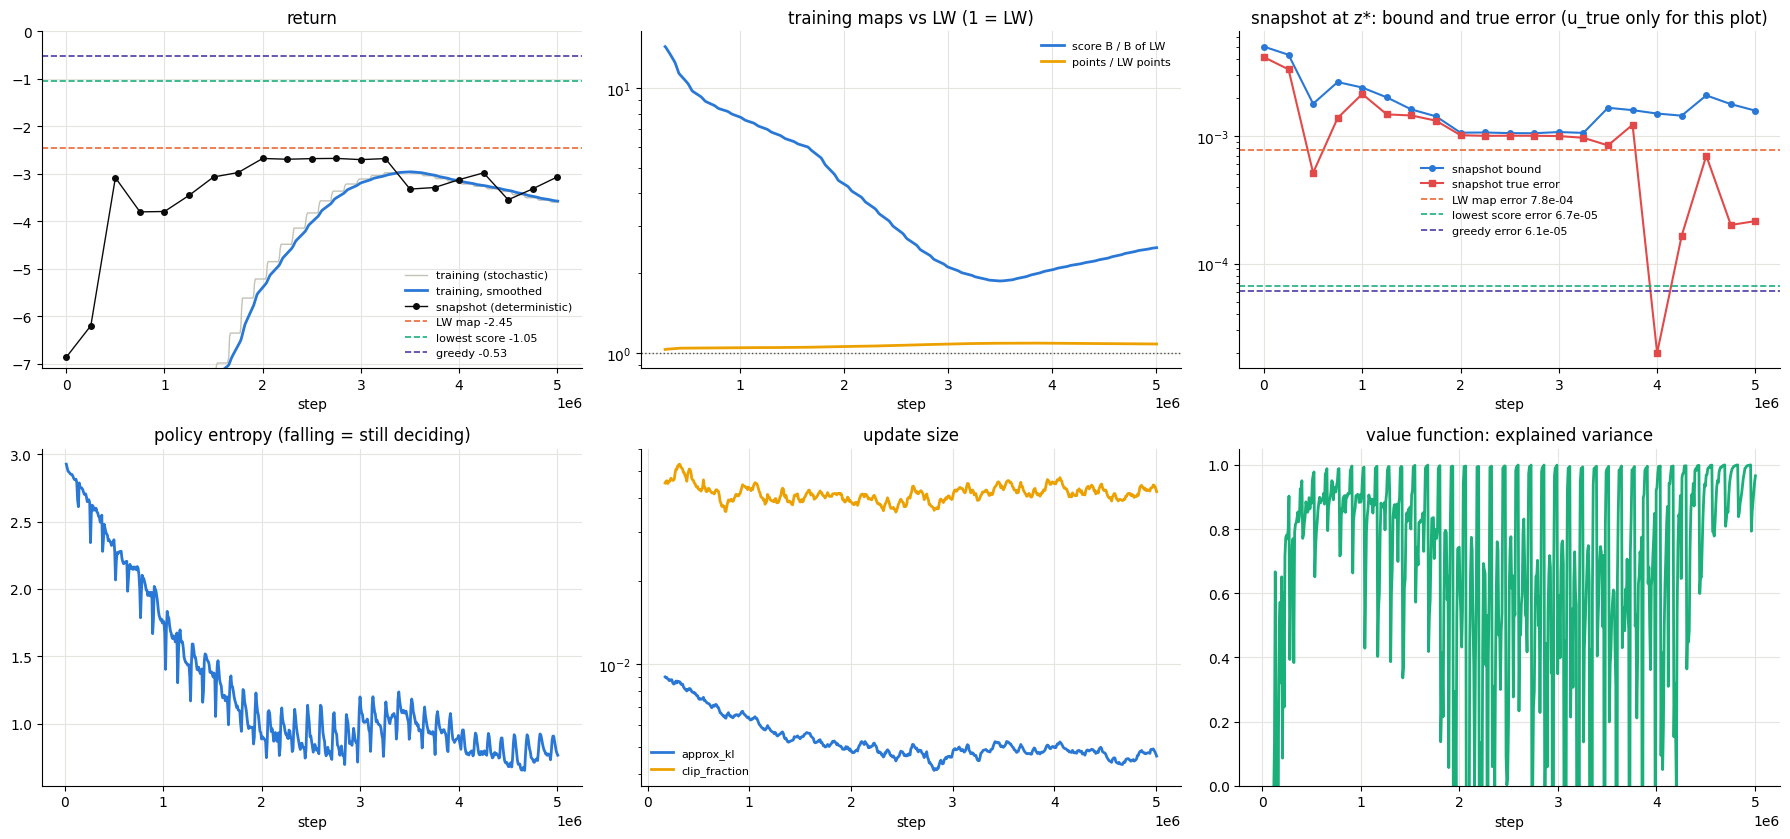

     rollout/ep_rew_mean:   -3.130 ->   -3.560 over the last 1M steps
         map/score_ratio:    2.042 ->    2.479 over the last 1M steps
        map/points_ratio:    1.088 ->    1.081 over the last 1M steps
      train/entropy_loss:   -0.934 ->   -0.803 over the last 1M steps


In [38]:
# ── Has the run converged? Training curves (tensorboard) + the deterministic snapshots, against the rules at Z_TRAIN ──
#   top:    return (training episodes, smoothed, and the snapshots) | score and points vs LW | snapshot bound and true error
#   bottom: PPO health: entropy (still falling = still deciding), approx KL and clip fraction, explained variance
#   converged ~ return, score ratio and entropy all flat over the last ~1M steps
import json, glob
from tensorboard.backend.event_processing.event_accumulator import EventAccumulator
RUN_DIR = run_dir                                                 # the run just trained (or any run folder)
Z_RUN, LAM_RUN = Z_TRAIN, LAM_PLOT

ea = EventAccumulator(sorted(glob.glob(os.path.join(RUN_DIR, "logs", "*")))[-1]); ea.Reload()
tb = lambda tag: (np.array([e.step for e in ea.Scalars(tag)]), np.array([e.value for e in ea.Scalars(tag)]))
smooth = lambda v, k=20: np.convolve(v, np.ones(k) / k, mode="valid") if len(v) > k else v
snaps = json.load(open(os.path.join(RUN_DIR, "snapshots.json")))
S = {k: np.array([s[k] for s in snaps], dtype=float) for k in ("step", "return", "points", "bound", "error")}

# the rules at the same query, as reference lines
base = {}
for name, rule in [("LW map", lw), ("lowest score", lowest_score), ("greedy", greedy_rule(LAM_RUN))]:
    mm = build_map(Z_RUN, rule); rep = report(mm)
    base[name] = dict(ret=-score_sum(mm) / EPS - LAM_RUN * (rep["points"] - 1) / n_lw(Z_RUN), **rep)
BC = {"LW map": "#eb6834", "lowest score": "#1baf7a", "greedy": "#4a3aa7"}

fig, ax = plt.subplots(2, 3, figsize=(18, 8.5))
st, v = tb("rollout/ep_rew_mean")
ax[0, 0].plot(st, v, color="#c3c2b7", lw=1, label="training (stochastic)")
ax[0, 0].plot(st[len(st) - len(smooth(v)):], smooth(v), color="#2a78d6", lw=2, label="training, smoothed")
ax[0, 0].plot(S["step"], S["return"], "o-", color="#0b0b0b", ms=4, lw=1, label="snapshot (deterministic)")
for n, b in base.items():
    ax[0, 0].axhline(b["ret"], color=BC[n], ls="--", lw=1.2, label=f"{n} {b['ret']:.2f}")
ax[0, 0].set_ylim(min(base["LW map"]["ret"], S["return"][-5:].min()) * 2, 0)
ax[0, 0].set_title("return"); ax[0, 0].legend(fontsize=8, frameon=False)

for tag, c, lab in [("map/score_ratio", "#2a78d6", "score B / B of LW"), ("map/points_ratio", "#eda100", "points / LW points")]:
    st, v = tb(tag)
    ax[0, 1].plot(st[len(st) - len(smooth(v)):], smooth(v), color=c, lw=2, label=lab)
ax[0, 1].axhline(1, color="#52514e", ls=":", lw=1); ax[0, 1].set_yscale("log")
ax[0, 1].set_title("training maps vs LW (1 = LW)"); ax[0, 1].legend(fontsize=8, frameon=False)

ax[0, 2].semilogy(S["step"], S["bound"], "o-", color="#2a78d6", ms=4, label="snapshot bound")
ax[0, 2].semilogy(S["step"], S["error"], "s-", color="#e34948", ms=4, label="snapshot true error")
for n, b in base.items():
    ax[0, 2].axhline(b["error"], color=BC[n], ls="--", lw=1.2, label=f"{n} error {b['error']:.1e}")
ax[0, 2].set_title("snapshot at z*: bound and true error (u_true only for this plot)"); ax[0, 2].legend(fontsize=8, frameon=False)

st, v = tb("train/entropy_loss"); ax[1, 0].plot(st, -v, color="#2a78d6", lw=2)
ax[1, 0].set_title("policy entropy (falling = still deciding)")
for tag, c in [("train/approx_kl", "#2a78d6"), ("train/clip_fraction", "#eda100")]:
    st, v = tb(tag); ax[1, 1].plot(st[len(st) - len(smooth(v)):], smooth(v), color=c, lw=2, label=tag.split("/")[1])
ax[1, 1].set_yscale("log"); ax[1, 1].set_title("update size"); ax[1, 1].legend(fontsize=8, frameon=False)
st, v = tb("train/explained_variance"); ax[1, 2].plot(st, v, color="#1baf7a", lw=2)
ax[1, 2].set_ylim(0, 1.05); ax[1, 2].set_title("value function: explained variance")
for a_ in ax.flat:
    a_.set_xlabel("step"); a_.spines[["top", "right"]].set_visible(False); a_.grid(True, color="#e5e4df", lw=0.8)
plt.tight_layout(); plt.show()

# ── Numbers: change over the last 1M steps (flat = converged) ──
for tag in ["rollout/ep_rew_mean", "map/score_ratio", "map/points_ratio", "train/entropy_loss"]:
    st, v = tb(tag)
    last, before = v[st >= st[-1] - 250_000].mean(), v[(st >= st[-1] - 1_250_000) & (st < st[-1] - 1_000_000)].mean()
    print(f"{tag:>24s}: {before:8.3f} -> {last:8.3f} over the last 1M steps")

## Comparisons
Run after training (both runs, shaping on and off). C1 and C2 compute, P1-P3 only draw.


In [39]:
# ══ Comparisons (after training): the agents, the rules and the classical solvers on the training query + 9 unseen ones ══
# ── C1. Every map method at every query (maps kept for the figures below) ──
#   AGENTS: run folders of trained agents (shaping on and off); each is loaded from checkpoints/ppo_final. Missing ones are skipped.
from collections import Counter
from sb3_contrib import MaskablePPO
AGENTS = {"agent, shaping":    os.path.join("runs10-22", "inflow_smooth_peak0.5_stop_shaping1_picard3_z25-75_lam1-1_seed1"),
          "agent, no shaping": os.path.join("runs10-22", "inflow_smooth_peak0.5_stop_shaping0_picard3_z25-75_lam1-1_seed1")}
AGENTS = {n: d for n, d in AGENTS.items() if os.path.exists(os.path.join(d, "checkpoints", "ppo_final.zip"))}
Z_TRAIN, LAM = (25, 75), 1.0
QUERIES_TEST = [(ix, it) for it in (50, 100, 150) for ix in (12, 25, 38)]
Z_ALL = [Z_TRAIN] + QUERIES_TEST

def agent_rule(path):
    model = MaskablePPO.load(os.path.join(path, "checkpoints", "ppo_final"), device="cpu")
    def make(z):
        env = run_policy(model, z, LAM)
        assert env.info["finished"], f"the agent did not finish the map at {z}"
        return env.m
    return make

RULES = {"LW map": lambda z: build_map(z, lw), "lowest score": lambda z: build_map(z, lowest_score),
         "greedy": lambda z: build_map(z, greedy_rule(LAM))}
RULES.update({n: agent_rule(d) for n, d in AGENTS.items()})
NAMES = list(RULES)
MAPS, REP = {}, {}                                       # MAPS[z][name] = map, REP[z][name] = points, stops, error, bound, return
t0 = time.time()
for z in Z_ALL:
    MAPS[z], REP[z] = {}, {}
    for name, make in RULES.items():
        m = make(z); rep = report(m)
        MAPS[z][name] = m
        REP[z][name] = dict(rep, ret=-score_sum(m) / EPS - LAM * (rep["points"] + rep["stops"] - 1) / n_lw(z))
    print(f"z* = {z}: done ({time.time() - t0:.0f} s)")
print("agents:", list(AGENTS) or "none found (train first)")


z* = (25, 75): done (15 s)
z* = (12, 50): done (23 s)
z* = (25, 50): done (32 s)
z* = (38, 50): done (40 s)
z* = (12, 100): done (62 s)
z* = (25, 100): done (83 s)
z* = (38, 100): done (104 s)
z* = (12, 150): done (138 s)
z* = (25, 150): done (171 s)
z* = (38, 150): done (203 s)
agents: ['agent, shaping', 'agent, no shaping']


In [40]:
# ── C2. Classical solvers at every query: true error at z* and evaluated points, grids 1-4x ──
#   Classical schemes run on their own grids, refined k = 1..4 (r = alpha dt/dx^2 kept fixed), with the same boundary data
#   (inflow / outflow Dirichlet values g_left, g_right in time). Burgers: each grid point uses its own value as the speed.
#     FD-3: forward Euler + central 2nd order | LW: Lax-Wendroff | CN: Crank-Nicolson (speed from the previous step)
#     FD-5 + RK4: 4th-order central in space, RK4 in time | WENO5 + RK3: WENO5-JS (Lax-Friedrichs splitting) + SSP-RK3,
#     its ghost nodes past the walls taken from u_true (more data than the others get: this favours WENO).
#   Evaluated points = grid values computed in z*'s dependency cone (RK: x stages; CN: the whole row, it is implicit).
#   Map methods run on the base grid; they also pay for the guess levels up to t*. u_true ONLY for reporting (and WENO ghosts).
from scipy.linalg import solve_banded
_gd = _gs.derivative()                                            # time derivative of the boundary data (RK stages)

def _weno5(vm2, vm1, v0, vp1, vp2):
    """WENO5-JS value at the interface on the vp1 side of v0."""
    q0, q1, q2 = (2 * vm2 - 7 * vm1 + 11 * v0) / 6, (-vm1 + 5 * v0 + 2 * vp1) / 6, (2 * v0 + 5 * vp1 - vp2) / 6
    b0 = 13 / 12 * (vm2 - 2 * vm1 + v0)**2 + 0.25 * (vm2 - 4 * vm1 + 3 * v0)**2
    b1 = 13 / 12 * (vm1 - 2 * v0 + vp1)**2 + 0.25 * (vm1 - vp1)**2
    b2 = 13 / 12 * (v0 - 2 * vp1 + vp2)**2 + 0.25 * (3 * v0 - 4 * vp1 + vp2)**2
    w0, w1, w2 = 0.1 / (1e-6 + b0)**2, 0.6 / (1e-6 + b1)**2, 0.3 / (1e-6 + b2)**2
    return (w0 * q0 + w1 * q1 + w2 * q2) / (w0 + w1 + w2)

def rhs(u, h, t, scheme):
    """du/dt at the nodes (walls: the time derivative of the boundary data)."""
    n = len(u)
    if scheme == "WENO5 + RK3":
        ue = np.r_[u_true(-h * np.arange(3, 0, -1), t), u, u_true(1 + h * np.arange(1, 4), t)]   # ue[j] = node j - 3
        am = np.abs(ue).max()
        fp, fm = 0.5 * (0.5 * ue**2 + am * ue), 0.5 * (0.5 * ue**2 - am * ue)
        j = np.arange(2, n + 3)
        F = _weno5(fp[j - 2], fp[j - 1], fp[j], fp[j + 1], fp[j + 2]) + _weno5(fm[j + 3], fm[j + 2], fm[j + 1], fm[j], fm[j - 1])
        c = np.arange(3, n + 3)
        du = -(F[1:] - F[:-1]) / h + alpha * (-ue[c + 2] + 16 * ue[c + 1] - 30 * ue[c] + 16 * ue[c - 1] - ue[c - 2]) / (12 * h**2)
    else:                                                          # FD-5: 4th-order central, 2nd order next to the walls
        u2, u1 = np.zeros(n), np.zeros(n)
        u2[1:-1], u1[1:-1] = u[2:] - 2 * u[1:-1] + u[:-2], (u[2:] - u[:-2]) / 2
        u2[2:-2] = (-u[4:] + 16 * u[3:-1] - 30 * u[2:-2] + 16 * u[1:-3] - u[:-4]) / 12
        u1[2:-2] = (-u[4:] + 8 * u[3:-1] - 8 * u[1:-3] + u[:-4]) / 12
        du = alpha * u2 / h**2 - u * u1 / h
    du[0], du[-1] = _gd(t)
    return du

def classical(scheme, k, z):
    """(evaluated points, true error at z*) on the grid refined k times."""
    n, h = (nx - 1) * k + 1, dx / k
    t_star, ix = z[1] * dt, z[0] * k
    u = u0(np.arange(n) * h)
    if scheme == "WENO5 + RK3":                                    # its own stable step: CFL 0.4, diffusion number 0.2
        steps = int(np.ceil(t_star / min(0.4 * h / A_MAX, 0.2 * h**2 / alpha))); tau_k = t_star / steps
    else:
        tau_k = dt / k**2 if scheme != "CN" else 4 * dt / k**2     # CN is implicit: 4x bigger steps
        steps = round(t_star / tau_k)
    r = alpha * tau_k / h**2
    for j in range(steps):
        t, t1 = j * tau_k, (j + 1) * tau_k
        if scheme == "WENO5 + RK3":
            u1 = u + tau_k * rhs(u, h, t, scheme)
            u2 = 0.75 * u + 0.25 * (u1 + tau_k * rhs(u1, h, t1, scheme))
            u = u / 3 + 2 / 3 * (u2 + tau_k * rhs(u2, h, t + tau_k / 2, scheme))
        elif scheme == "FD-5 + RK4":
            k1 = rhs(u, h, t, scheme); k2 = rhs(u + tau_k * k1 / 2, h, t + tau_k / 2, scheme)
            k3 = rhs(u + tau_k * k2 / 2, h, t + tau_k / 2, scheme); k4 = rhs(u + tau_k * k3, h, t1, scheme)
            u = u + tau_k * (k1 + 2 * k2 + 2 * k3 + k4) / 6
        else:
            nu = u[1:-1] * tau_k / h
            d2, d1 = u[2:] - 2 * u[1:-1] + u[:-2], (u[2:] - u[:-2]) / 2
            new = u.copy()
            if scheme == "FD-3":
                new[1:-1] = u[1:-1] + r * d2 - nu * d1
            elif scheme == "LW":
                new[1:-1] = u[1:-1] + (r + nu**2 / 2) * d2 - nu * d1
            elif scheme == "CN":                                   # speed from the previous step (linearised CN)
                lo, up = -r / 2 - nu / 4, -r / 2 + nu / 4          # coefficients of u_{i-1}, u_{i+1} at the new time
                b = u[1:-1] + r / 2 * d2 - nu / 2 * d1
                b[0] -= lo[0] * g_left(t1); b[-1] -= up[-1] * g_right(t1)
                ab = np.zeros((3, n - 2)); ab[0, 1:], ab[1], ab[2, :-1] = up[:-1], 1 + r, lo[1:]
                new[1:-1] = solve_banded((1, 1), ab, b)
            new[0], new[-1] = g_left(t1), g_right(t1)
            u = new
    err = abs(u[ix] - Ug(z))
    spread = {"FD-3": 1, "LW": 1, "FD-5 + RK4": 8, "WENO5 + RK3": 9}.get(scheme)   # cone growth per step (RK: all stages)
    if spread is None:
        pts = (n - 2) * steps                                      # CN couples the whole row at every step
    else:
        pts = sum(min(n - 2, ix + spread * j) - max(1, ix - spread * j) + 1 for j in range(steps))
        pts *= {"FD-5 + RK4": 4, "WENO5 + RK3": 3}.get(scheme, 1)
    return pts, err

SCHEMES = ["FD-3", "LW", "CN", "FD-5 + RK4", "WENO5 + RK3"]
CL, t0 = {}, time.time()
for z in Z_ALL:
    CL[z] = {s: [classical(s, k, z) for k in (1, 2, 3, 4)] for s in SCHEMES}      # [(points, error)] for grids 1-4x
    print(f"z* = {z}: done ({time.time() - t0:.0f} s)")


z* = (25, 75): done (35 s)
z* = (12, 50): done (61 s)
z* = (25, 50): done (88 s)
z* = (38, 50): done (114 s)
z* = (12, 100): done (159 s)
z* = (25, 100): done (205 s)
z* = (38, 100): done (249 s)
z* = (12, 150): done (312 s)
z* = (25, 150): done (374 s)
z* = (38, 150): done (435 s)


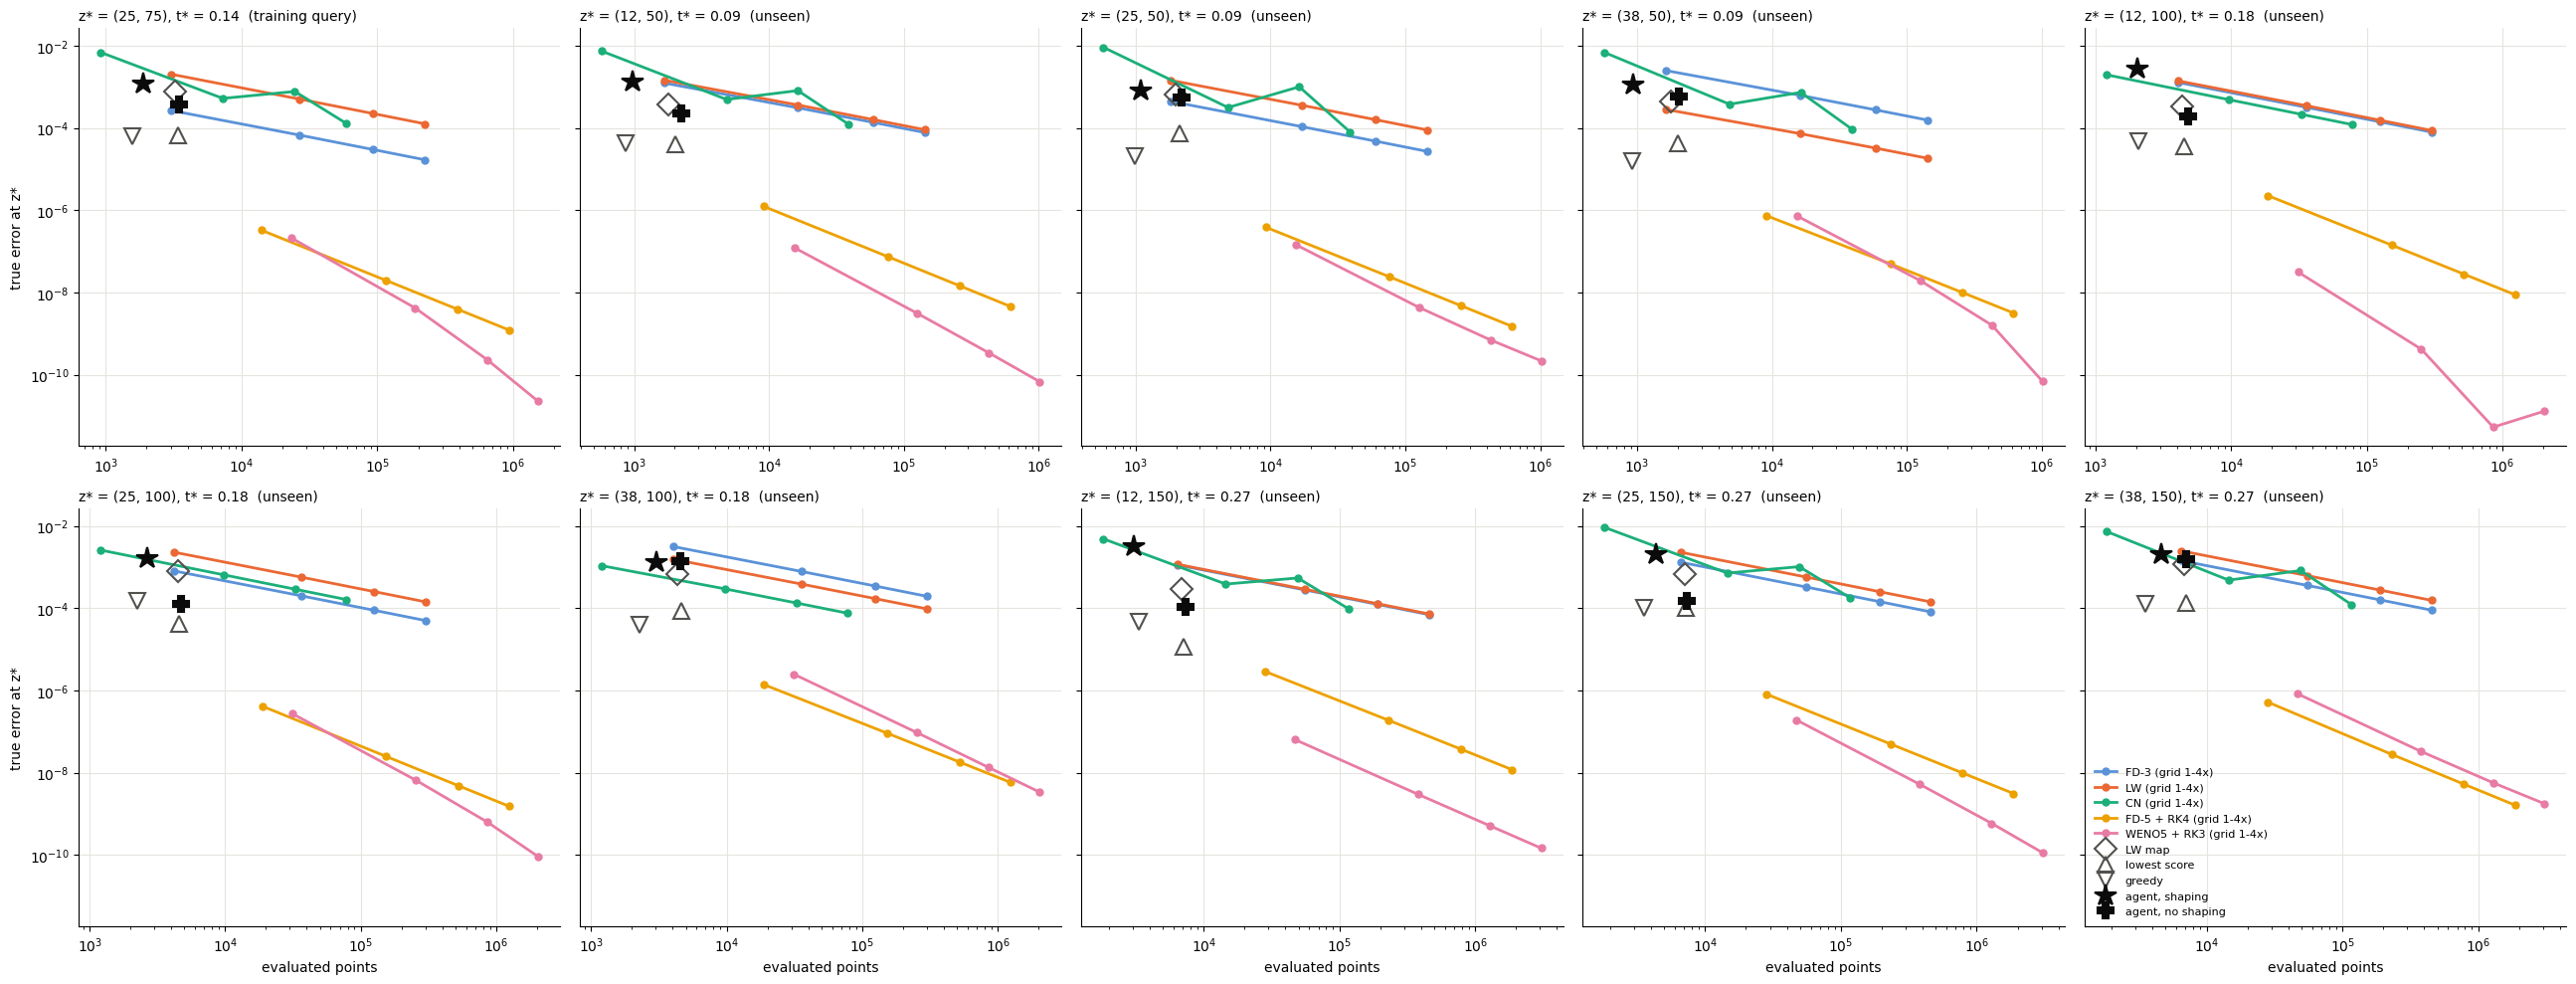

In [41]:
# ── P1. True error at z* vs evaluated points, every query: classical solvers (grids 1-4x) and the map methods ──
#   map methods also pay for the guesses up to t* (all three: the stop cost needs the two extra ones)
COL = {"FD-3": "#5a92d8", "LW": "#eb6834", "CN": "#1baf7a", "FD-5 + RK4": "#eda100", "WENO5 + RK3": "#e87ba4"}
MK  = {"LW map": "D", "lowest score": "^", "greedy": "v"}
MK.update({n: mk for n, mk in zip(AGENTS, ["*", "P", "X"])})
GUESS_COST = {z: round((G_COARSE + G_COARSE2 + G_COARSE4) * z[1] / (nt - 1)) for z in Z_ALL}

def error_points_panel(ax, z, legend=False):
    for s in SCHEMES:
        ax.loglog(*zip(*CL[z][s]), "o-", color=COL[s], lw=2, ms=5, label=f"{s} (grid 1-4x)")
    for name, mk in MK.items():
        r, ag = REP[z][name], name in AGENTS
        ax.loglog(r["points"] + GUESS_COST[z], r["error"], mk, color="#0b0b0b" if ag else "#52514e",
                  ms=16 if mk == "*" else 11, mfc="#0b0b0b" if ag else "none", mew=1.5, label=name)
    tag = "training query" if z == Z_TRAIN else "unseen"
    ax.set_title(f"z* = {z}, t* = {z[1] * dt:.2f}  ({tag})", loc="left", fontsize=10)
    ax.grid(True, which="major", color="#e5e4df", lw=0.8); ax.spines[["top", "right"]].set_visible(False)
    if legend:
        ax.legend(fontsize=8, frameon=False, loc="lower left")

fig, axes = plt.subplots(2, 5, figsize=(26, 10), sharey=True)
for ax, z in zip(axes.flat, Z_ALL):
    error_points_panel(ax, z, legend=(z == Z_ALL[-1]))
for ax in axes[1]:
    ax.set_xlabel("evaluated points")
for ax in axes[:, 0]:
    ax.set_ylabel("true error at z*")
plt.tight_layout(); plt.show()


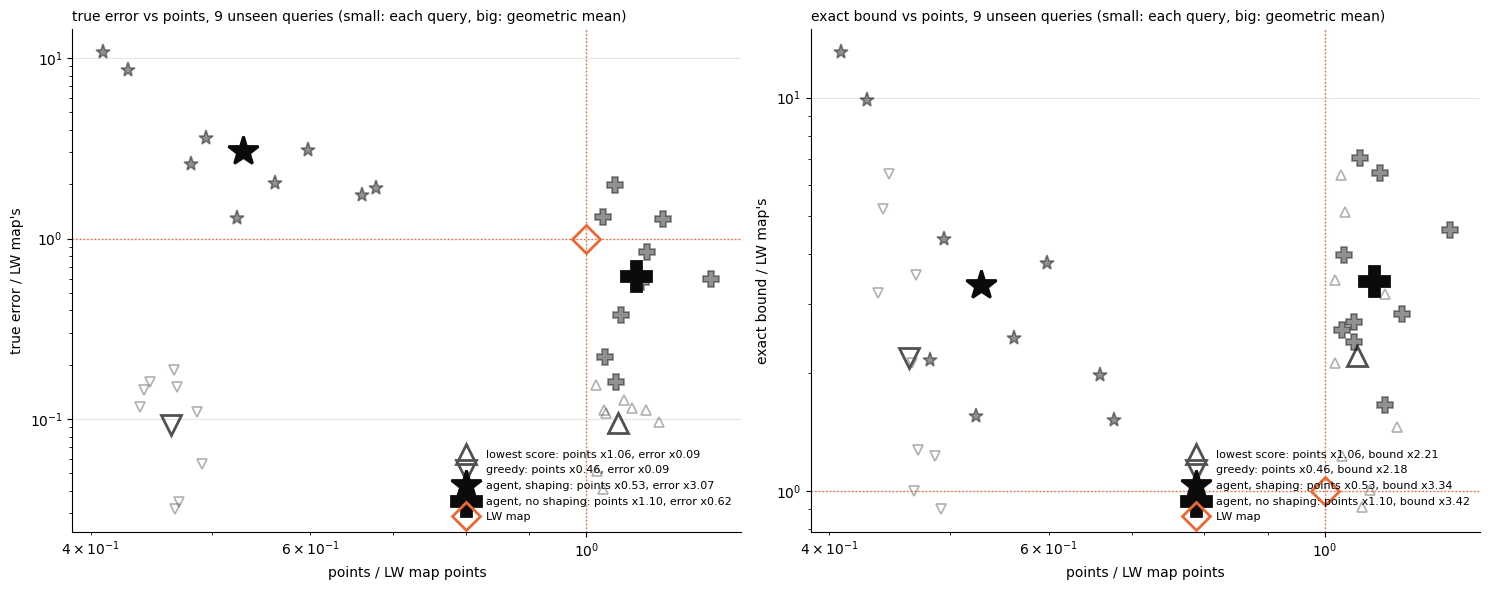

unseen queries (9): each / LW map (geometric mean); wins = true error below the LW map's
       lowest score: points x1.06 | bound x2.21 | error x0.09 | wins 9/9 | stops per map 0
             greedy: points x0.46 | bound x2.18 | error x0.09 | wins 9/9 | stops per map 0
     agent, shaping: points x0.53 | bound x3.34 | error x3.07 | wins 0/9 | stops per map 164
  agent, no shaping: points x1.10 | bound x3.42 | error x0.62 | wins 6/9 | stops per map 0


In [42]:
# ── P2. All unseen queries on one plot: each map method relative to the LW map of the same query (LW map = 1, 1) ──
#   small markers: one per query; big markers: geometric mean over the unseen queries. Lower left = better than LW.
gm = lambda v: float(np.exp(np.mean(np.log(v))))
METHODS = [n for n in NAMES if n != "LW map"]
fig, axes = plt.subplots(1, 2, figsize=(15, 6), sharex=True)
for ax, k in zip(axes, ("error", "bound")):
    for name in METHODS:
        ag = name in AGENTS
        px = [REP[z][name]["points"] / REP[z]["LW map"]["points"] for z in QUERIES_TEST]
        py = [REP[z][name][k] / REP[z]["LW map"][k] for z in QUERIES_TEST]
        c = "#0b0b0b" if ag else "#52514e"
        ax.loglog(px, py, MK[name], color=c, ms=11 if ag else 7, mfc=c if ag else "none", mew=1.2, alpha=0.45)
        ax.loglog(gm(px), gm(py), MK[name], color=c, ms=22 if ag else 14, mfc=c if ag else "none", mew=2,
                  label=f"{name}: points x{gm(px):.2f}, {k} x{gm(py):.2f}")
    ax.loglog(1, 1, "D", color="#eb6834", ms=14, mfc="none", mew=2, label="LW map")
    ax.axhline(1, color="#eb6834", ls=":", lw=1); ax.axvline(1, color="#eb6834", ls=":", lw=1)
    ax.set_xlabel("points / LW map points"); ax.set_ylabel(f"{'true error' if k == 'error' else 'exact bound'} / LW map's")
    ax.set_title(f"{'true error' if k == 'error' else 'exact bound'} vs points, {len(QUERIES_TEST)} unseen queries "
                 "(small: each query, big: geometric mean)", loc="left", fontsize=10)
    ax.grid(True, which="major", color="#e5e4df", lw=0.8); ax.spines[["top", "right"]].set_visible(False)
    ax.legend(fontsize=8, frameon=False, loc="lower right")
plt.tight_layout(); plt.show()

print(f"unseen queries ({len(QUERIES_TEST)}): each / LW map (geometric mean); wins = true error below the LW map's")
for name in METHODS:
    r = {k: gm([REP[z][name][k] / REP[z]["LW map"][k] for z in QUERIES_TEST]) for k in ("points", "bound", "error")}
    wins = sum(REP[z][name]["error"] < REP[z]["LW map"]["error"] for z in QUERIES_TEST)
    stops = np.mean([REP[z][name]["stops"] for z in QUERIES_TEST])
    print(f"  {name:>17s}: points x{r['points']:.2f} | bound x{r['bound']:.2f} | error x{r['error']:.2f} | "
          f"wins {wins}/{len(QUERIES_TEST)} | stops per map {stops:.0f}")


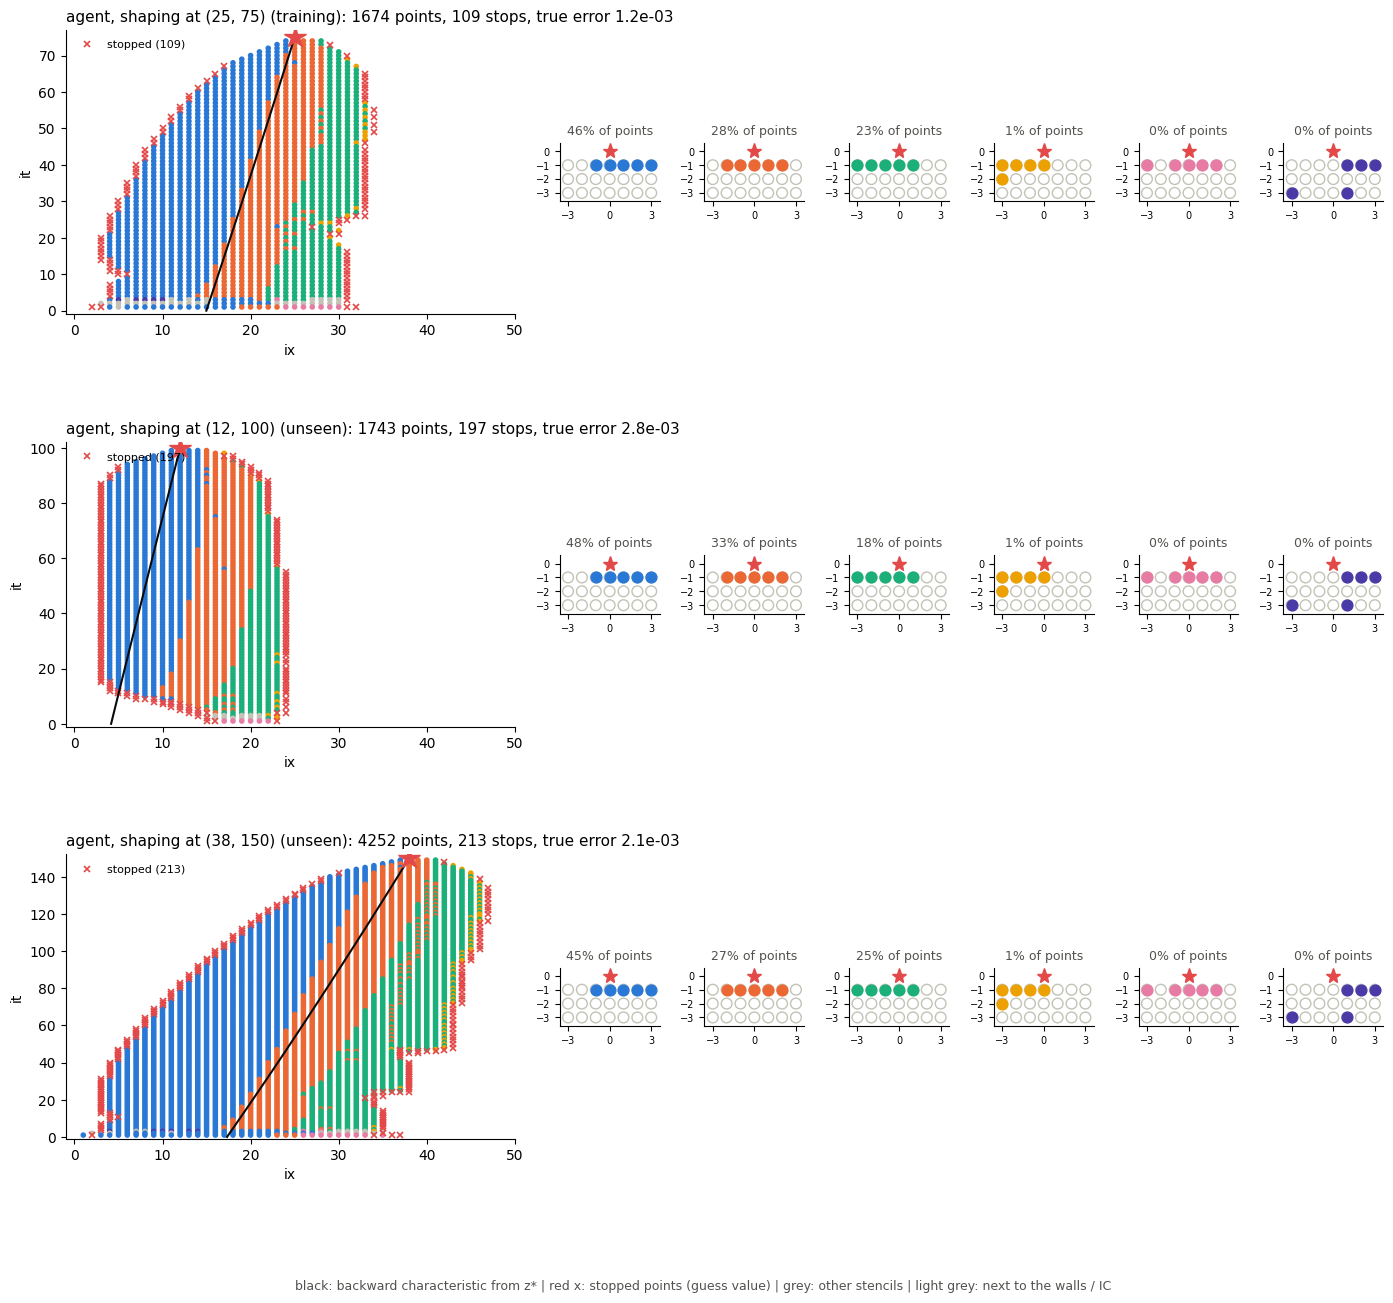

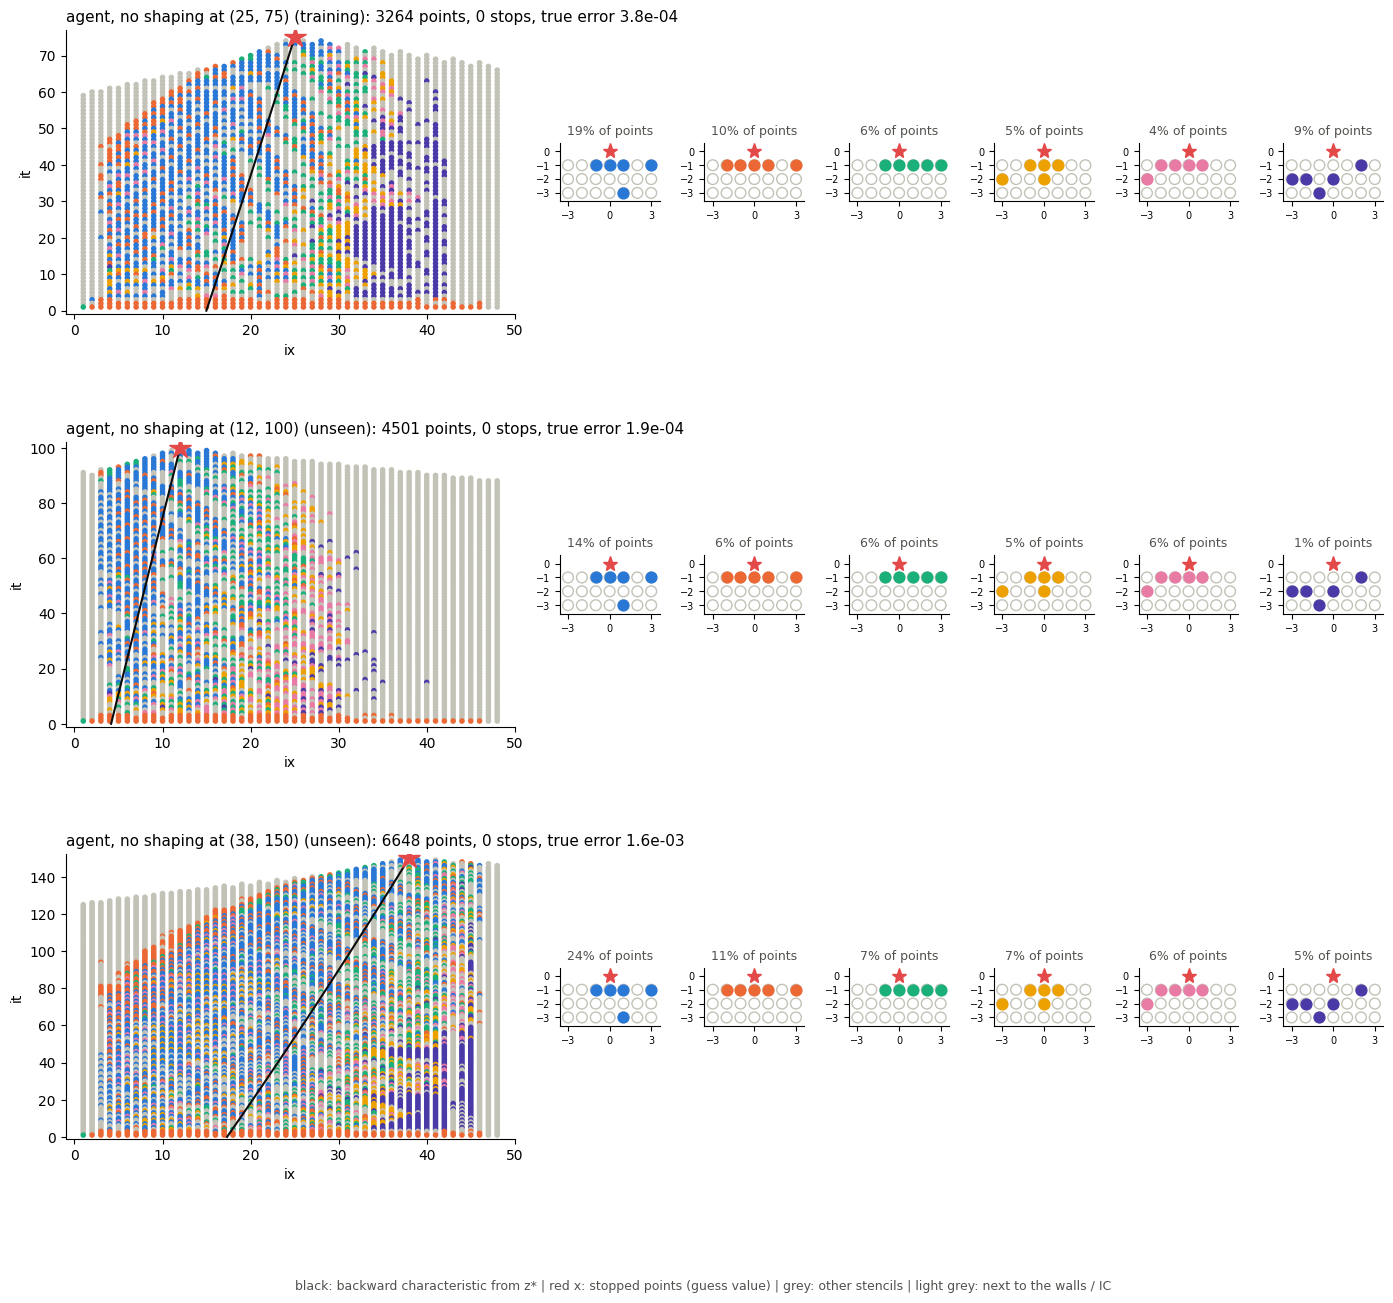

In [43]:
# ── P3. Where each agent puts stencils and stops, at the training query and two unseen ones ──
#   same colour = same stencil in every panel (the 6 most used by that agent); grey: other stencils;
#   light grey: next to the walls / IC; red x: stopped points (they take the guess value);
#   black line: the backward characteristic from z* (dx/dt = u, exact solution, for the picture only)
OTHER, EDGE = "#c3c2b7", "#e5e4df"
TOP_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#4a3aa7"]
Z_MAP = [Z_TRAIN, (12, 100), (38, 150)]

def stencil_cells(p, nbs):
    """Window cells of p's stencil, or None next to the walls / IC (cells there are moved onto the known data)."""
    offs = [(q[0] - p[0], q[1] - p[1]) for q in nbs]
    return tuple(sorted(WINDOW.index(o) for o in offs)) if all(o in WINDOW for o in offs) else None

def characteristic(z, sub=4):
    """Backward characteristic from z*: x(t) with dx/dt = u(x, t), Euler steps of dt / sub, in grid units."""
    x, xs = z[0] * dx, [z[0]]
    for it in range(z[1], 0, -1):
        for j in range(sub):
            x -= u_true(x, (it - j / sub) * dt)[0] * dt / sub
        xs.append(x / dx)
    return np.array(xs), np.arange(z[1], -1, -1)

for name in AGENTS:
    count = Counter(c for z in Z_MAP for p, (nbs, w) in MAPS[z][name]["stencil"].items() if (c := stencil_cells(p, nbs)) is not None)
    TOP6  = [c for c, _ in count.most_common(6)]
    color = {c: TOP_COLORS[i] for i, c in enumerate(TOP6)}
    fig = plt.figure(figsize=(17, 4.8 * len(Z_MAP)))
    gs_ = fig.add_gridspec(len(Z_MAP), 7, width_ratios=[4.5, 1, 1, 1, 1, 1, 1], hspace=0.45, wspace=0.3)
    for row, z in enumerate(Z_MAP):
        m = MAPS[z][name]
        cells = {p: stencil_cells(p, nbs) for p, (nbs, w) in m["stencil"].items()}
        used = Counter(c for c in cells.values() if c is not None); n_used = max(sum(used.values()), 1)
        ax = fig.add_subplot(gs_[row, 0])
        P = np.array(list(cells))
        ax.scatter(P[:, 0], P[:, 1], s=9, c=[EDGE if c is None else color.get(c, OTHER) for c in cells.values()])
        if m["stopped"]:
            S = np.array(list(m["stopped"]))
            ax.plot(S[:, 0], S[:, 1], "x", color="#e34948", ms=5, mew=1.2, label=f"stopped ({len(S)})")
            ax.legend(fontsize=8, frameon=False, loc="upper left")
        ax.plot(*characteristic(z), "-", color="#0b0b0b", lw=1.5)
        ax.plot(*z, "*", color="#e34948", ms=16)
        r = REP[z][name]
        ax.set_xlim(-1, nx); ax.set_ylim(-1, z[1] + 2); ax.set_xlabel("ix"); ax.set_ylabel("it")
        ax.set_title(f"{name} at {z} ({'training' if z == Z_TRAIN else 'unseen'}): {r['points']} points, {r['stops']} stops, "
                     f"true error {r['error']:.1e}", loc="left", fontsize=11)
        ax.spines[["top", "right"]].set_visible(False)
        for i, c in enumerate(TOP6):
            g_ = fig.add_subplot(gs_[row, i + 1])
            g_.scatter(*np.array(WINDOW).T, s=60, facecolors="none", edgecolors=OTHER)
            g_.scatter(*np.array([WINDOW[k] for k in c]).T, s=60, color=TOP_COLORS[i])
            g_.plot(0, 0, "*", color="#e34948", ms=11)
            g_.set_xlim(-3.6, 3.6); g_.set_ylim(-3.6, 0.6); g_.set_aspect("equal")
            g_.set_xticks([-3, 0, 3]); g_.set_yticks([0, -1, -2, -3]); g_.tick_params(labelsize=7)
            g_.set_title(f"{used[c] / n_used:.0%} of points", fontsize=9, color="#52514e")
            g_.spines[["top", "right"]].set_visible(False)
    fig.text(0.5, 0.005, "black: backward characteristic from z* | red x: stopped points (guess value) | grey: other stencils | "
             "light grey: next to the walls / IC", ha="center", fontsize=9, color="#52514e")
    plt.show()
